# Medical Appointment No-Show Prediction & Demand Forecasting

**Domain:** Healthcare Operations & Resource Management  |  **Author:** Barath Srinath A (GUVI Data Science Capstone)

---

## 📌 Problem

The CER rehabilitation clinic (southern Brazil) loses about **31.8%** of its appointments to no-shows, far above the typical 10–20%. Daily demand is unpredictable across specialties and cities, so staffing is hard.

This notebook builds two complementary models:

| Task | Type | Output |
|---|---|---|
| **No-show prediction** | Binary classification | A calibrated no-show probability (risk score) for every appointment |
| **Demand forecasting** | Time-series regression | Daily appointment volume, overall and by specialty |

Both models are deployed in one Streamlit app (`app.py`).

## 🎯 Targets from the project brief

| Model | Metric | Target |
|---|---|---|
| Classifier | F1-score | > 0.70 |
| Classifier | ROC-AUC | > 0.75 |
| Forecaster | MAPE | < 20% |
| Forecaster | R² | > 0.65 |

The final section compares the results with these targets honestly.

## 🗂 Project files

- `Medical_Appointments_Project_Fixed.ipynb` — this notebook (cleaning, features, EDA, models, evaluation, insights)
- `medical_utils.py` — feature and forecasting helpers shared by the notebook and the app
- `app.py` — Streamlit application (run with `streamlit run app.py`)
- `data/`, `models/`, `charts/`, `reports/` — everything this notebook produces


## 0. Setup

In [1]:
import inspect
import json
import os
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

import medical_utils as mu          # helpers shared with the Streamlit app

RAW_FILE = "Medical_appointment_data.csv"
DATA_DIR, MODEL_DIR, CHART_DIR, REPORT_DIR = "data", "models", "charts", "reports"
for folder in (DATA_DIR, MODEL_DIR, CHART_DIR, REPORT_DIR):
    os.makedirs(folder, exist_ok=True)

RANDOM_STATE = 42
TARGETS = {"F1": 0.70, "ROC_AUC": 0.75, "MAPE_pct": 20.0, "R2": 0.65}


def save_fig(name):
    """Save the current figure into charts/ and show it."""
    plt.tight_layout()
    plt.savefig(f"{CHART_DIR}/{name}.png", dpi=120, bbox_inches="tight")
    plt.show()
    plt.close()


def takeaway(text):
    print(f"\n>> Takeaway: {text}\n")


print("Setup complete.")


Setup complete.


## 1. Load & Inspect Data

In [2]:
raw = pd.read_csv(RAW_FILE)

print("=" * 70)
print("1. DATASET OVERVIEW")
print("=" * 70)
print(f"Rows: {raw.shape[0]:,}   Columns: {raw.shape[1]}")
print(f"Date range: {raw['appointment_date_continuous'].min()} to {raw['appointment_date_continuous'].max()}")
display(raw.head())

print("\nMISSING VALUES (% of rows)")
missing = (raw.isna().mean() * 100).round(1)
print(missing[missing > 0].sort_values(ascending=False).to_string())

target_share = raw["no_show"].str.lower().value_counts(normalize=True).mul(100).round(1)
print(f"\nTARGET: no_show = yes for {target_share['yes']}% of appointments (class imbalance)")

print("\n" + "=" * 70)
print("2. DATA QUIRKS FOUND DURING INSPECTION")
print("=" * 70)
is_real = raw["place"].isin(mu.REAL_CITIES)
n_other = raw["place"].notna().sum() - is_real.sum()
n_other_names = raw.loc[raw["place"].notna() & ~is_real, "place"].nunique()
print(f"* place: {raw['place'].nunique():,} distinct values, but the clinic serves only {len(mu.REAL_CITIES)} cities.")
print(f"  - {is_real.sum():,} rows ({is_real.mean():.1%}) carry one of the {len(mu.REAL_CITIES)} real city names")
print(f"  - {n_other:,} rows ({n_other / len(raw):.1%}) carry one of {n_other_names:,} made-up names (e.g. 'New Michael')")
print(f"  - {raw['place'].isna().sum():,} rows ({raw['place'].isna().mean():.1%}) are missing")
same = (raw["rainy_day_before"] == raw["storm_day_before"]).mean()
print(f"* rainy_day_before and storm_day_before are identical in {same:.2%} of rows and equal 1 for "
      f"{raw['storm_day_before'].mean():.0%} of rows: they behave like one flag.")
print(f"* disability has {raw['disability'].isna().mean():.1%} missing values plus {(raw['disability'] == ' ').sum()} blank (' ') entries.")
print(f"* appointment_shift is not tied to the hour: both shifts cover hours "
      f"{raw['appointment_time'].min()} to {raw['appointment_time'].max()}.")


1. DATASET OVERVIEW
Rows: 109,593   Columns: 26
Date range: 2020-01-01 to 2021-05-12


,specialty,appointment_time,gender,no_show,disability,place,appointment_shift,age,under_12_years_old,over_60_years_old,patient_needs_companion,average_temp_day,average_rain_day,max_temp_day,max_rain_day,rainy_day_before,storm_day_before,rain_intensity,heat_intensity,appointment_date_continuous,Hipertension,Diabetes,Alcoholism,Handcap,Scholarship,SMS_received
0,psychotherapy,17,F,yes,intellectual,Lake Marvinville,afternoon,9.0,1,0,1,23.18,0.00,27.5,0.0,1,1,no_rain,warm,2020-01-01,0,0,0,0,0,0
1,NaN,7,M,no,intellectual,ITAPEMA,morning,11.0,1,0,1,14.31,0.02,16.5,0.6,1,1,no_rain,cold,2020-01-01,0,0,0,0,0,0
2,speech therapy,16,M,no,intellectual,ITAJAÍ,afternoon,8.0,1,0,1,21.61,0.01,29.9,0.2,1,1,no_rain,warm,2020-01-01,0,0,0,0,0,0
3,speech therapy,14,M,yes,intellectual,Sarahside,afternoon,9.0,1,0,1,21.39,0.11,24.1,1.4,1,1,moderate,mild,2020-01-01,0,0,0,0,0,1
4,physiotherapy,8,M,no,motor,ITAJAÍ,morning,NaN,0,0,0,20.15,0.02,23.1,0.2,1,1,no_rain,mild,2020-01-01,0,0,0,0,0,0



MISSING VALUES (% of rows)
age                 21.0
specialty           18.4
disability          15.1
place               10.5
max_rain_day         2.1
average_temp_day     2.0
average_rain_day     2.0
max_temp_day         2.0

TARGET: no_show = yes for 31.8% of appointments (class imbalance)

2. DATA QUIRKS FOUND DURING INSPECTION
* place: 26,289 distinct values, but the clinic serves only 13 cities.
  - 44,412 rows (40.5%) carry one of the 13 real city names
  - 53,642 rows (48.9%) carry one of 26,276 made-up names (e.g. 'New Michael')
  - 11,539 rows (10.5%) are missing
* rainy_day_before and storm_day_before are identical in 99.93% of rows and equal 1 for 94% of rows: they behave like one flag.
* disability has 15.1% missing values plus 419 blank (' ') entries.
* appointment_shift is not tied to the hour: both shifts cover hours 7 to 18.


## 2. Data Cleaning

Every missing value gets an explicit strategy. 'Missing' is kept as its own category where it carries information (disability, specialty, place), instead of being replaced by the most common value.

In [3]:
def clean_data(raw_df):
    """Clean the raw table. Missing values are kept as explicit categories, because 'missing' itself
    turned out to be informative (see the no-show rates in section 4)."""
    df = raw_df.copy()
    df.columns = [c.strip().lower() for c in df.columns]
    before = len(df)
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"Duplicate rows removed: {before - len(df)}")

    out = pd.DataFrame(index=df.index)
    out["date"] = pd.to_datetime(df["appointment_date_continuous"])
    out["no_show_target"] = (df["no_show"].str.strip().str.lower() == "yes").astype(int)

    # age: numeric, missing -> median + a flag so the model can see that age was unknown
    age = pd.to_numeric(df["age"], errors="coerce")
    out["age_missing"] = age.isna().astype(int)
    out["age"] = age.fillna(age.median())

    # categorical columns: missing -> explicit 'unknown' / 'missing' categories (not the most common value)
    out["specialty"] = (df["specialty"].str.strip().str.lower().replace(mu.SPECIALTY_MAP).fillna("unknown"))
    disability = df["disability"].astype("string").str.strip().str.lower()
    out["disability"] = disability.mask(disability == "", "blank").fillna("missing").astype(str)
    out["place"] = np.where(df["place"].isna(), mu.MISSING_PLACE,
                            np.where(df["place"].isin(mu.REAL_CITIES), df["place"], mu.OTHER_PLACE))
    out["gender"] = df["gender"].str.strip().str.upper()
    out["appointment_shift"] = df["appointment_shift"].str.strip().str.lower()
    out["rain_intensity"] = df["rain_intensity"].str.strip().str.lower()
    out["heat_intensity"] = df["heat_intensity"].str.strip().str.lower()

    # weather: the same date has the same weather, so fill from other rows of that date, then the overall median
    weather_cols = ["average_temp_day", "average_rain_day", "max_temp_day", "max_rain_day"]
    out["weather_missing"] = df[weather_cols].isna().any(axis=1).astype(int)
    for c in weather_cols:
        by_date = df.groupby("appointment_date_continuous")[c].transform("mean")
        out[c] = df[c].fillna(by_date).fillna(df[c].median())

    # integer / binary columns
    for c in ["appointment_time", "under_12_years_old", "over_60_years_old", "patient_needs_companion",
              "rainy_day_before", "storm_day_before", "hipertension", "diabetes", "alcoholism", "handcap",
              "scholarship", "sms_received"]:
        out[c] = pd.to_numeric(df[c], errors="coerce").fillna(0).astype(int)

    bad_age = ~out["age"].between(0, 110)
    print(f"Invalid ages removed: {int(bad_age.sum())}")
    return out[~bad_age].reset_index(drop=True)


clean = clean_data(raw)
assert clean.isna().sum().sum() == 0, "missing values left"

print("\nCLEANING REPORT")
strategy = pd.DataFrame([
    ("age", f"{raw['age'].isna().mean():.1%}", "median + age_missing flag"),
    ("specialty", f"{raw['specialty'].isna().mean():.1%}", "explicit 'unknown' category"),
    ("disability", f"{raw['disability'].isna().mean():.1%}", "explicit 'missing' category ('blank' kept separate)"),
    ("place", f"{raw['place'].isna().mean():.1%}", "'MISSING'; made-up names grouped as 'OTHER_NAME'"),
    ("weather columns", f"{raw['average_temp_day'].isna().mean():.1%}", "mean of the same date, then median + weather_missing flag"),
], columns=["Column", "Missing", "Strategy"])
display(strategy)
print(f"Final shape: {clean.shape}")
clean.to_csv(f"{DATA_DIR}/medical_appointments_clean.csv", index=False)


Duplicate rows removed: 36


Invalid ages removed: 0

CLEANING REPORT


,Column,Missing,Strategy
0,age,21.0%,median + age_missing flag
1,specialty,18.4%,explicit 'unknown' category
2,disability,15.1%,explicit 'missing' category ('blank' kept sepa...
3,place,10.5%,'MISSING'; made-up names grouped as 'OTHER_NAME'
4,weather columns,2.0%,"mean of the same date, then median + weather_m..."


Final shape: (109557, 28)


## 3. Feature Engineering

The feature code lives in `medical_utils.py`, so the app builds features for a new appointment in exactly the same way.

In [4]:
feats = mu.engineer_features(clean)

print("Engineered features (code shared with the Streamlit app):\n")
print(inspect.getsource(mu.engineer_features))

new_cols = ["age_group", "appointment_period", "weather_risk_score", "health_score", "month", "day_of_week", "is_weekend"]
display(feats[new_cols].describe(include="all").T[["count", "unique", "top", "mean", "min", "max"]])
print(f"Final shape: {feats.shape}")
feats.to_csv(f"{DATA_DIR}/medical_appointments_featured.csv", index=False)


Engineered features (code shared with the Streamlit app):

def engineer_features(df):
    """Add the engineered columns. Expects the cleaned columns plus a `date` column."""
    d = df.copy()
    d["age_group"] = pd.cut(d["age"], bins=[-1, 12, 18, 35, 50, 65, 200],
                            labels=["child", "teen", "young_adult", "adult", "senior_adult", "elderly"]).astype(str)
    hour = d["appointment_time"]
    d["appointment_period"] = np.select([hour < 10, hour < 13, hour < 16],
                                        ["early_morning", "late_morning", "early_afternoon"], default="late_afternoon")
    d["weather_risk_score"] = d["rainy_day_before"] + d["storm_day_before"]
    d["health_score"] = d[["hipertension", "diabetes", "alcoholism", "handcap"]].sum(axis=1)
    dt = pd.to_datetime(d["date"])
    d["month"] = dt.dt.month
    d["day_of_week"] = dt.dt.dayofweek
    d["is_weekend"] = (d["day_of_week"] >= 5).astype(int)
    return d



,count,unique,top,mean,min,max
age_group,109557,6,child,NaN,NaN,NaN
appointment_period,109557,4,early_afternoon,NaN,NaN,NaN
weather_risk_score,109557.0,NaN,NaN,1.875252,0.0,2.0
health_score,109557.0,NaN,NaN,0.109733,0.0,4.0
month,109557.0,NaN,NaN,4.976359,1.0,12.0
day_of_week,109557.0,NaN,NaN,2.909928,0.0,6.0
is_weekend,109557.0,NaN,NaN,0.256141,0.0,1.0


Final shape: (109557, 35)


## 4. Exploratory Data Analysis

Every takeaway below is calculated from the data.

4.1 OVERVIEW


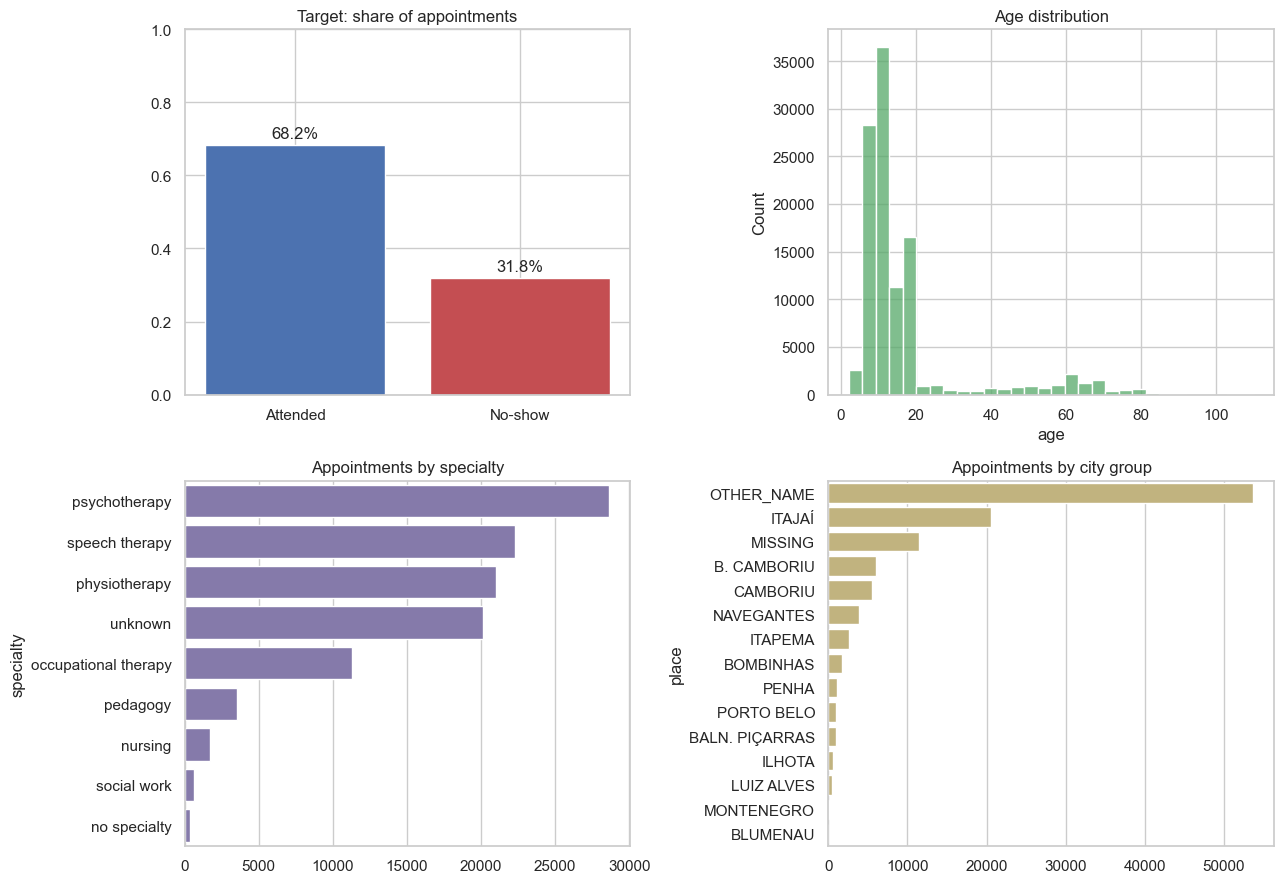


>> Takeaway: The median patient is 12 years old (a mostly paediatric clinic); psychotherapy is the busiest specialty (26%); 49% of rows carry a made-up city name.

4.2 WHAT DRIVES NO-SHOWS?


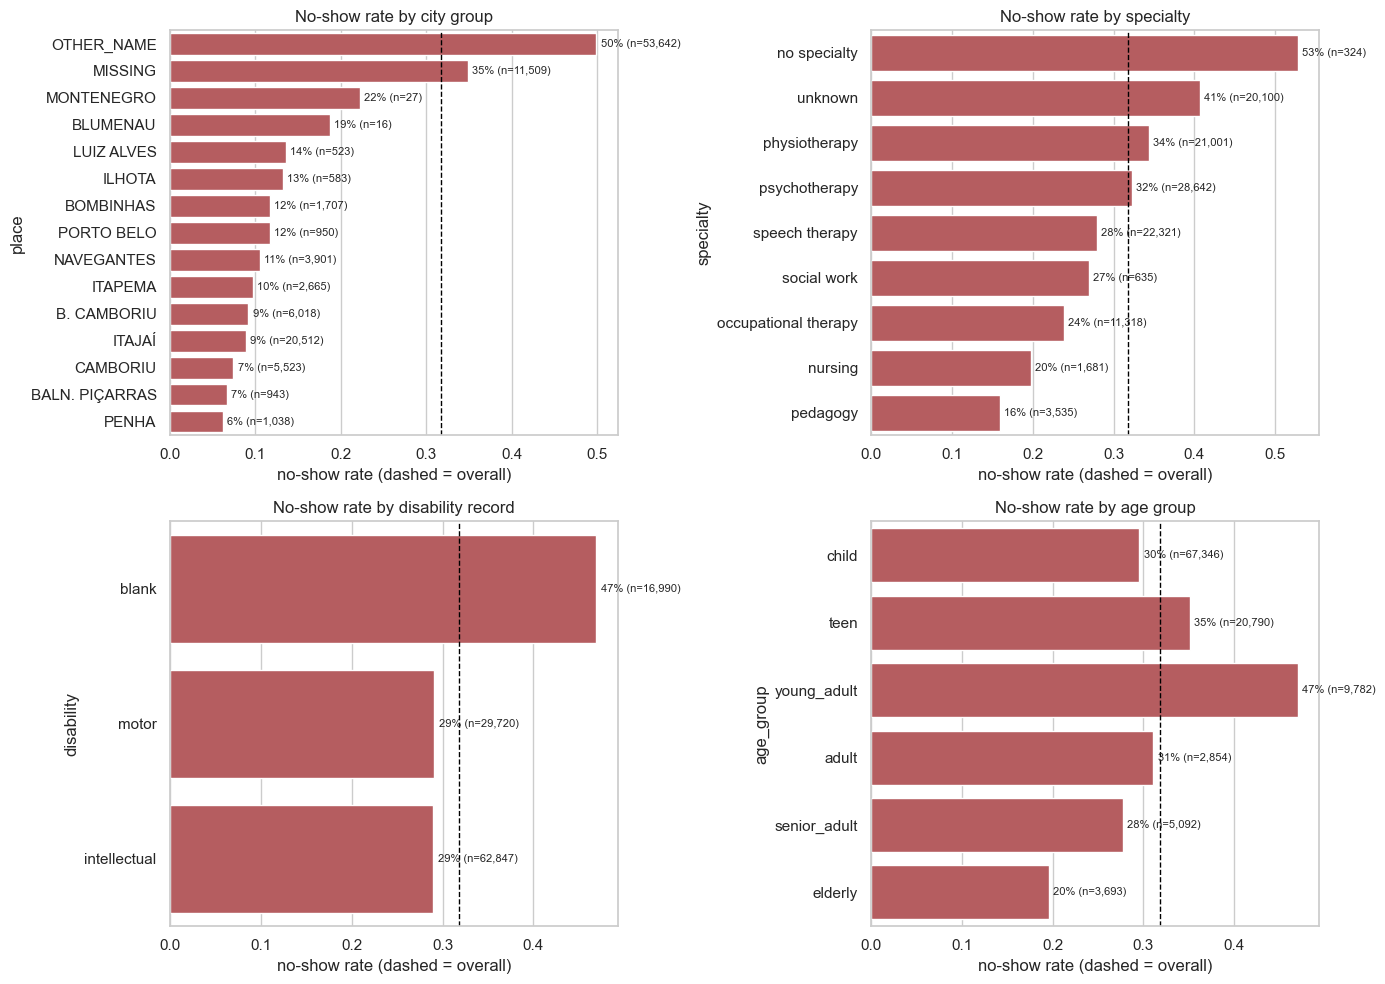


>> Takeaway: Appointments with a made-up city name have a 50% no-show rate, against 9% for the 13 real cities - the strongest pattern in the data (probably a recording artifact, worth checking with the clinic). Blank disability (47%) and missing specialty (41%) also predict no-shows, so 'unknown' must be kept as a category.


Health conditions, reminders and weather:


,No-show rate if 0,No-show rate if 1,Rows with 1
Factor,,,
Hypertension,0.321,0.264,6366
Diabetes,0.319,0.276,2625
Alcoholism,0.319,0.282,2032
Handicap,0.318,0.307,999
Scholarship,0.318,0.318,6039
SMS reminder received,0.318,0.319,34165
Needs companion,0.348,0.290,56966
Storm/rain day before,0.564,0.302,102731



>> Takeaway: SMS reminders show no measurable effect (31.9% vs 31.8%), chronic conditions are linked to slightly fewer no-shows, and the storm/rain-day-before flag separates 56% from 30%.



In [5]:
print("=" * 70)
print("4.1 OVERVIEW")
print("=" * 70)
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
rate = feats["no_show_target"].mean()
ax[0, 0].bar(["Attended", "No-show"], [1 - rate, rate], color=["#4C72B0", "#C44E52"])
ax[0, 0].set_title("Target: share of appointments"); ax[0, 0].set_ylim(0, 1)
for i, v in enumerate([1 - rate, rate]):
    ax[0, 0].text(i, v + 0.02, f"{v:.1%}", ha="center")
sns.histplot(feats["age"], bins=30, ax=ax[0, 1], color="#55A868"); ax[0, 1].set_title("Age distribution")
spec_counts = feats["specialty"].value_counts()
sns.barplot(x=spec_counts.values, y=spec_counts.index, ax=ax[1, 0], color="#8172B2"); ax[1, 0].set_title("Appointments by specialty")
city_counts = feats["place"].value_counts()
sns.barplot(x=city_counts.values, y=city_counts.index, ax=ax[1, 1], color="#CCB974"); ax[1, 1].set_title("Appointments by city group")
save_fig("eda_overview")
takeaway(f"The median patient is {feats['age'].median():.0f} years old (a mostly paediatric clinic); "
         f"{spec_counts.index[0]} is the busiest specialty ({spec_counts.iloc[0] / len(feats):.0%}); "
         f"{(feats['place'] == mu.OTHER_PLACE).mean():.0%} of rows carry a made-up city name.")

print("=" * 70)
print("4.2 WHAT DRIVES NO-SHOWS?")
print("=" * 70)
target = "no_show_target"


def no_show_by(col, order=None):
    t = feats.groupby(col)[target].agg(["mean", "size"]).rename(columns={"mean": "no_show_rate", "size": "appointments"})
    return t.sort_values("no_show_rate", ascending=False) if order is None else t.loc[order]


by_city = no_show_by("place")
by_spec = no_show_by("specialty")
by_dis = no_show_by("disability")
by_age = no_show_by("age_group", ["child", "teen", "young_adult", "adult", "senior_adult", "elderly"])
fig, ax = plt.subplots(2, 2, figsize=(14, 10))
for a, (t, title) in zip(ax.ravel(), [(by_city, "No-show rate by city group"), (by_spec, "No-show rate by specialty"),
                                      (by_dis, "No-show rate by disability record"), (by_age, "No-show rate by age group")]):
    sns.barplot(x=t["no_show_rate"], y=t.index, ax=a, color="#C44E52")
    a.axvline(rate, color="black", linestyle="--", linewidth=1)
    a.set_title(title); a.set_xlabel("no-show rate (dashed = overall)")
    for i, (r, n) in enumerate(zip(t["no_show_rate"], t["appointments"])):
        a.text(r + 0.005, i, f"{r:.0%} (n={n:,})", va="center", fontsize=8)
save_fig("eda_no_show_drivers")
by_city.to_csv(f"{REPORT_DIR}/no_show_by_city.csv"); by_spec.to_csv(f"{REPORT_DIR}/no_show_by_specialty.csv")
real_rate = feats.loc[feats["place"].isin(mu.REAL_CITIES), target].mean()
takeaway(f"Appointments with a made-up city name have a {by_city.loc[mu.OTHER_PLACE, 'no_show_rate']:.0%} no-show rate, against "
         f"{real_rate:.0%} for the 13 real cities - the strongest pattern in the data (probably a recording artifact, worth checking with the clinic). "
         f"Blank disability ({by_dis.loc['blank', 'no_show_rate']:.0%}) and missing specialty "
         f"({by_spec.loc['unknown', 'no_show_rate']:.0%}) also predict no-shows, so 'unknown' must be kept as a category.")

print("\nHealth conditions, reminders and weather:")
rows = []
for label, col in [("Hypertension", "hipertension"), ("Diabetes", "diabetes"), ("Alcoholism", "alcoholism"),
                   ("Handicap", "handcap"), ("Scholarship", "scholarship"), ("SMS reminder received", "sms_received"),
                   ("Needs companion", "patient_needs_companion"), ("Storm/rain day before", "storm_day_before")]:
    g = feats.groupby(col)[target].mean()
    rows.append({"Factor": label, "No-show rate if 0": g.get(0, np.nan), "No-show rate if 1": g.get(1, np.nan),
                 "Rows with 1": int((feats[col] == 1).sum())})
factors = pd.DataFrame(rows).set_index("Factor").round(3)
display(factors)
factors.to_csv(f"{REPORT_DIR}/no_show_by_factor.csv")
sms = factors.loc["SMS reminder received"]
takeaway(f"SMS reminders show no measurable effect ({sms['No-show rate if 1']:.1%} vs {sms['No-show rate if 0']:.1%}), "
         f"chronic conditions are linked to slightly fewer no-shows, and the storm/rain-day-before flag separates "
         f"{factors.loc['Storm/rain day before', 'No-show rate if 0']:.0%} from {factors.loc['Storm/rain day before', 'No-show rate if 1']:.0%}.")


4.3 DEMAND PATTERNS


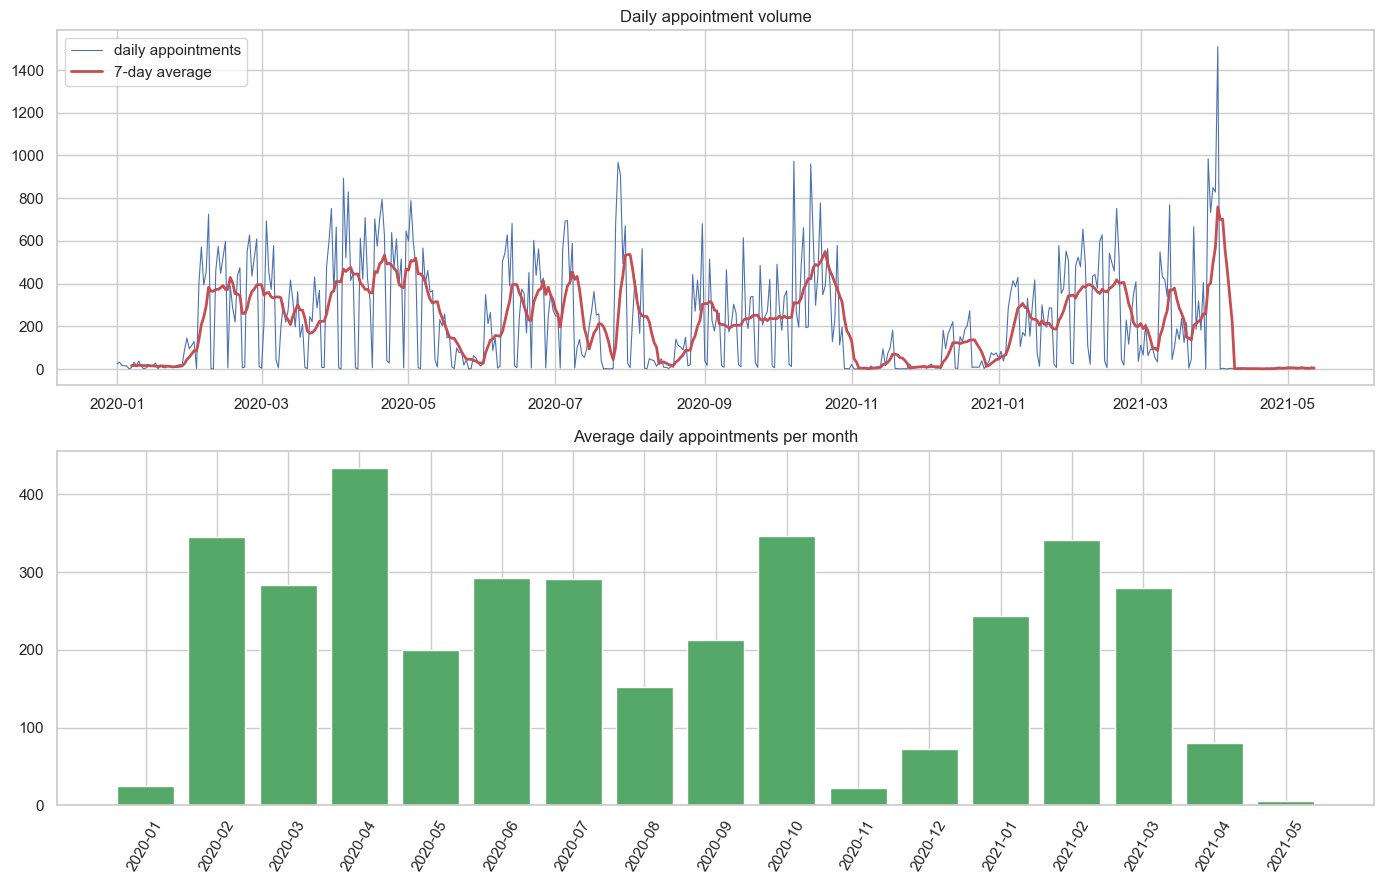


>> Takeaway: Demand is very uneven: it ranges from 1 to 1,510 a day (average 220); 185 of 498 days have under 30 appointments, with long quiet spells such as 2021-05 (average 5).



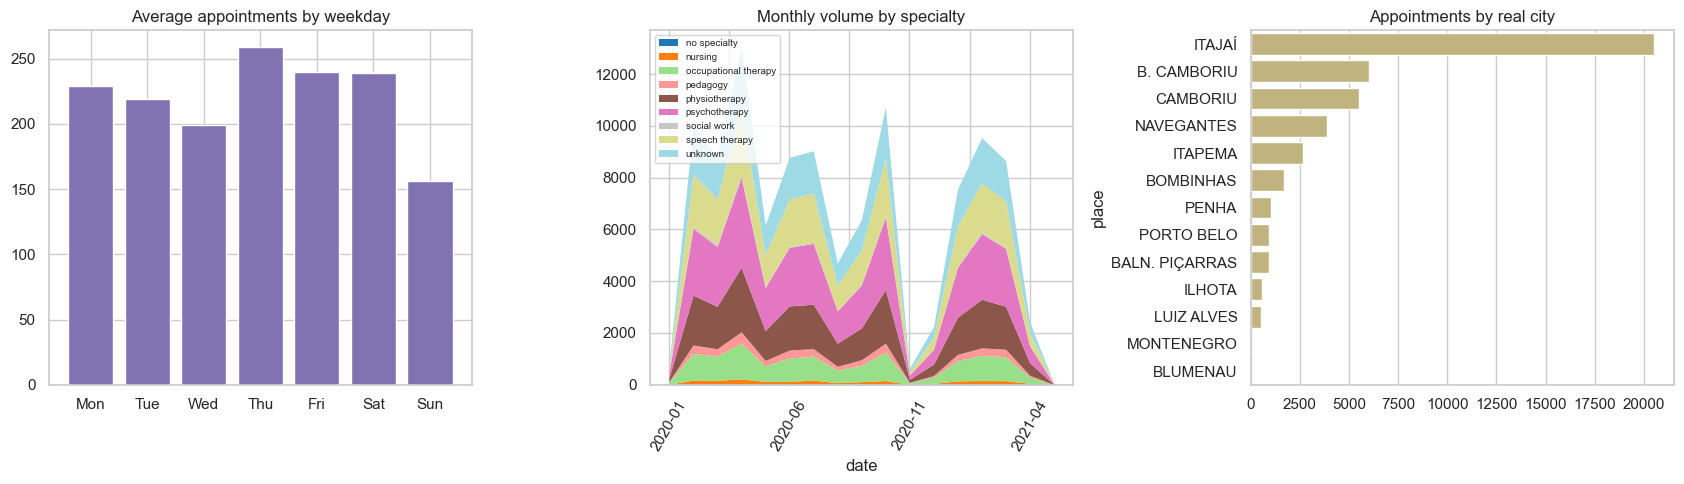


>> Takeaway: Busiest weekday: Thu (259); quietest: Sun (156). Psychotherapy, speech therapy and physiotherapy carry 66% of the work. Itajaí alone has 46% of the appointments in the 13 cities.

4.4 DOES WEATHER MOVE DEMAND?
average_temp_day    0.02
average_rain_day   -0.01
max_rain_day       -0.02
storm_day_before    0.02


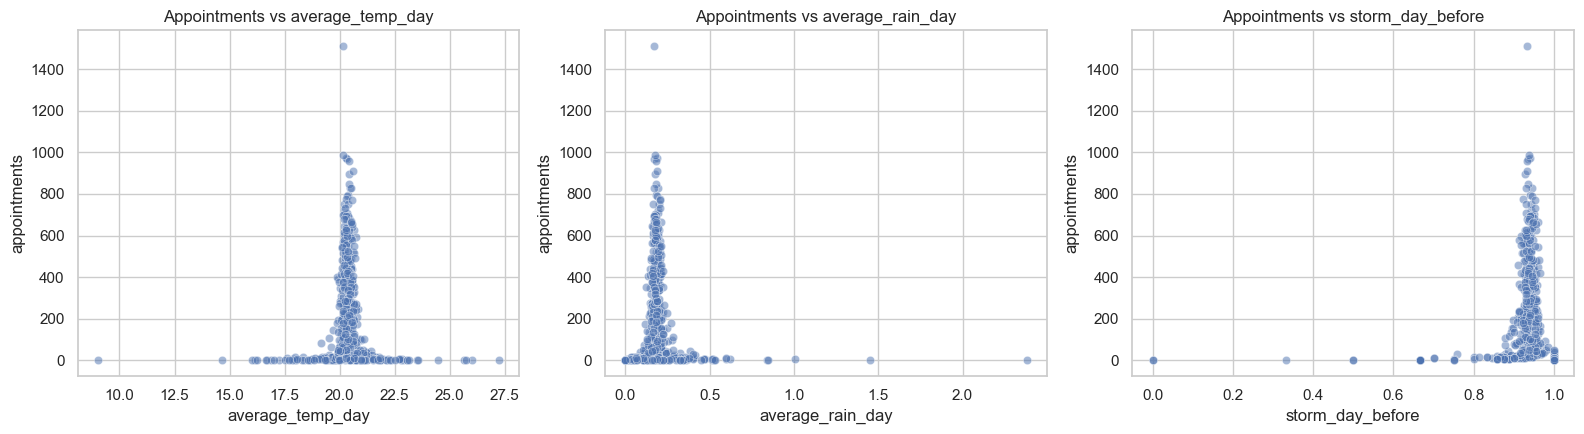


>> Takeaway: Weather on its own is only loosely related to daily volume, but the forecasting section shows that adding it still improves the model a lot (it helps the model recognise busy and quiet periods).

4.5 CORRELATIONS


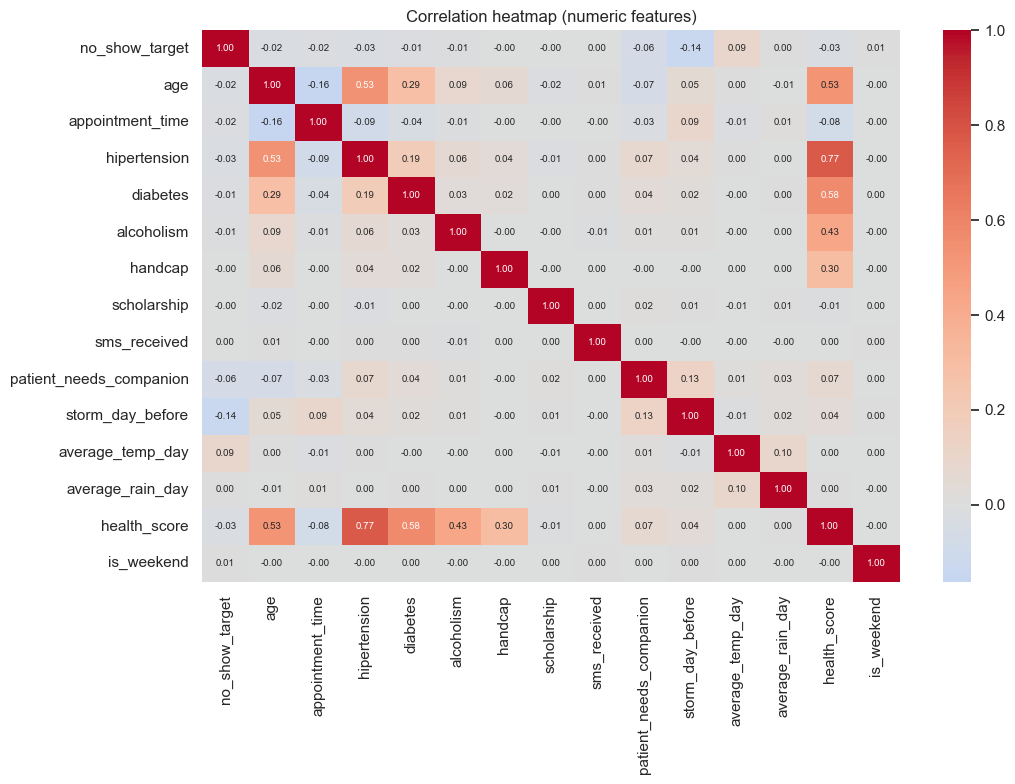


>> Takeaway: Linear correlations with no-show are weak (largest: storm_day_before -0.14), so tree-based models that capture interactions are worth comparing with the linear baseline.



In [6]:
print("=" * 70)
print("4.3 DEMAND PATTERNS")
print("=" * 70)
daily_counts = feats.groupby("date").size().rename("appointments")
fig, ax = plt.subplots(2, 1, figsize=(14, 9))
ax[0].plot(daily_counts.index, daily_counts.values, color="#4C72B0", linewidth=0.8, label="daily appointments")
ax[0].plot(daily_counts.index, daily_counts.rolling(7).mean(), color="#C44E52", linewidth=2, label="7-day average")
ax[0].set_title("Daily appointment volume"); ax[0].legend()
monthly = daily_counts.groupby(daily_counts.index.to_period("M")).agg(["mean", "max"])
ax[1].bar(monthly.index.astype(str), monthly["mean"], color="#55A868"); ax[1].set_title("Average daily appointments per month")
ax[1].tick_params(axis="x", rotation=60)
save_fig("eda_daily_demand")
quiet = daily_counts[daily_counts < 30]
takeaway(f"Demand is very uneven: it ranges from {daily_counts.min()} to {daily_counts.max():,} a day "
         f"(average {daily_counts.mean():.0f}); {len(quiet)} of {len(daily_counts)} days have under 30 appointments, "
         f"with long quiet spells such as {monthly['mean'].idxmin()} (average {monthly['mean'].min():.0f}).")

weekday_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
by_weekday = daily_counts.groupby(daily_counts.index.dayofweek).mean()
spec_month = feats.groupby([feats["date"].dt.to_period("M").astype(str), "specialty"]).size().unstack(fill_value=0)
by_city_volume = feats["place"].value_counts()
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
ax[0].bar(weekday_names, by_weekday.values, color="#8172B2"); ax[0].set_title("Average appointments by weekday")
spec_month.plot.area(ax=ax[1], linewidth=0, colormap="tab20"); ax[1].set_title("Monthly volume by specialty")
ax[1].legend(fontsize=7, loc="upper left"); ax[1].tick_params(axis="x", rotation=60)
real_volume = by_city_volume[by_city_volume.index.isin(mu.REAL_CITIES)]
sns.barplot(x=real_volume.values, y=real_volume.index, ax=ax[2], color="#CCB974"); ax[2].set_title("Appointments by real city")
save_fig("eda_demand_patterns")
by_weekday.rename(index=dict(enumerate(weekday_names))).to_csv(f"{REPORT_DIR}/demand_by_weekday.csv", header=["avg_daily_appointments"])
spec_share = (feats["specialty"].value_counts(normalize=True) * 100).round(1)
spec_share.to_csv(f"{REPORT_DIR}/demand_by_specialty.csv", header=["share_pct"])
real_volume.to_csv(f"{REPORT_DIR}/demand_by_city.csv", header=["appointments"])
takeaway(f"Busiest weekday: {weekday_names[int(by_weekday.idxmax())]} ({by_weekday.max():.0f}); quietest: "
         f"{weekday_names[int(by_weekday.idxmin())]} ({by_weekday.min():.0f}). Psychotherapy, speech therapy and physiotherapy carry "
         f"{spec_share[['psychotherapy', 'speech therapy', 'physiotherapy']].sum():.0f}% of the work. "
         f"{real_volume.index[0].title()} alone has {real_volume.iloc[0] / real_volume.sum():.0%} of the appointments in the 13 cities.")

print("=" * 70)
print("4.4 DOES WEATHER MOVE DEMAND?")
print("=" * 70)
weather_daily = feats.groupby("date")[mu.WEATHER_COLS].mean()
wd = pd.concat([daily_counts, weather_daily], axis=1)
corr = wd.corr()["appointments"].drop("appointments").round(2)
print(corr.to_string())
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, c in zip(ax, ["average_temp_day", "average_rain_day", "storm_day_before"]):
    sns.scatterplot(x=wd[c], y=wd["appointments"], ax=a, alpha=0.5); a.set_title(f"Appointments vs {c}")
save_fig("eda_weather_vs_demand")
takeaway("Weather on its own is only loosely related to daily volume, but the forecasting section shows that adding it still "
         "improves the model a lot (it helps the model recognise busy and quiet periods).")

print("=" * 70)
print("4.5 CORRELATIONS")
print("=" * 70)
num = feats[["no_show_target", "age", "appointment_time", "hipertension", "diabetes", "alcoholism", "handcap", "scholarship",
             "sms_received", "patient_needs_companion", "storm_day_before", "average_temp_day", "average_rain_day",
             "health_score", "is_weekend"]]
plt.figure(figsize=(11, 8))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Correlation heatmap (numeric features)")
save_fig("eda_correlation_heatmap")
top_corr = num.corr()["no_show_target"].drop("no_show_target").abs().sort_values(ascending=False).head(3)
takeaway(f"Linear correlations with no-show are weak (largest: {top_corr.index[0]} {num.corr()['no_show_target'][top_corr.index[0]]:.2f}), "
         "so tree-based models that capture interactions are worth comparing with the linear baseline.")


## 5. No-Show Classification

**Plan**

1. Split the data three ways (stratified, so every part keeps the 31.8% no-show share): **60% train**, **20% validation** (choose the model, calibrate it, pick the decision threshold), **20% test** (reported only once).
2. Handle the class imbalance with **class weights** (and compare with a model that ignores it).
3. Compare **four algorithms**: Logistic Regression, Random Forest, XGBoost, LightGBM.
4. Turn the best model's scores into a **calibrated probability (risk score)** and tune the F1-optimal threshold on validation data.
5. Explain the model (feature importance), check robustness over time, and save it.

In [7]:
from lightgbm import LGBMClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.frozen import FrozenEstimator
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

CAT, NUM = mu.CLS_CATEGORICAL, mu.CLS_NUMERIC
X = feats[CAT + NUM]
y = feats["no_show_target"]

X_trainval, X_test, y_trainval, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(X_trainval, y_trainval, test_size=0.25, stratify=y_trainval, random_state=RANDOM_STATE)

split_table = pd.DataFrame({"Rows": [len(X_train), len(X_val), len(X_test)],
                            "No-show rate": [y_train.mean(), y_val.mean(), y_test.mean()]},
                           index=["Train (60%)", "Validation (20%)", "Test (20%)"]).round(4)
display(split_table)
print("Features used:", len(CAT), "categorical +", len(NUM), "numeric")
print("Dropped on purpose: the date itself and the year, so the model cannot memorise specific days.")


def make_preprocessor(scale=False):
    return ColumnTransformer([("num", StandardScaler() if scale else "passthrough", NUM),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])


def best_threshold(y_true, proba):
    grid = np.arange(0.05, 0.95, 0.01)
    scores = [f1_score(y_true, proba >= t) for t in grid]
    return float(grid[int(np.argmax(scores))])


def scores_at(y_true, proba, threshold):
    pred = proba >= threshold
    return {"Precision": precision_score(y_true, pred), "Recall": recall_score(y_true, pred),
            "F1 (no-show class)": f1_score(y_true, pred), "F1 (weighted)": f1_score(y_true, pred, average="weighted"),
            "F1 (macro)": f1_score(y_true, pred, average="macro")}


,Rows,No-show rate
Train (60%),65733,0.3179
Validation (20%),21912,0.3179
Test (20%),21912,0.3179


Features used: 9 categorical + 23 numeric
Dropped on purpose: the date itself and the year, so the model cannot memorise specific days.


### 5.2 Compare algorithms with the imbalance handled

In [8]:
neg_pos = float((y_train == 0).sum() / (y_train == 1).sum())
candidates = {
    "Logistic Regression (class weights)": Pipeline([("prep", make_preprocessor(scale=True)),
        ("model", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    "Random Forest (class weights)": Pipeline([("prep", make_preprocessor()),
        ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced_subsample",
                                         n_jobs=-1, random_state=RANDOM_STATE))]),
    "XGBoost (scale_pos_weight)": Pipeline([("prep", make_preprocessor()),
        ("model", XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.08, subsample=0.9, colsample_bytree=0.8,
                                scale_pos_weight=neg_pos, eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1))]),
    "LightGBM (class weights)": Pipeline([("prep", make_preprocessor()),
        ("model", LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=63, class_weight="balanced",
                                 subsample=0.9, colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=-1, verbose=-1))]),
}
# the same XGBoost without any imbalance handling, to show what the class weights change
baseline = Pipeline([("prep", make_preprocessor()),
                     ("model", XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.08, subsample=0.9, colsample_bytree=0.8,
                                             eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1))])

rows, fitted = [], {}
for name, pipe in {**candidates, "XGBoost (NO imbalance handling)": baseline}.items():
    t0 = time.perf_counter()
    pipe.fit(X_train, y_train)
    p_val, p_test = pipe.predict_proba(X_val)[:, 1], pipe.predict_proba(X_test)[:, 1]
    thr = best_threshold(y_val, p_val)
    s05, st = scores_at(y_test, p_test, 0.5), scores_at(y_test, p_test, thr)
    rows.append({"Model": name, "ROC-AUC": roc_auc_score(y_test, p_test), "PR-AUC": average_precision_score(y_test, p_test),
                 "F1 @ 0.5": s05["F1 (no-show class)"], "Tuned threshold": thr, "Precision": st["Precision"], "Recall": st["Recall"],
                 "F1 (tuned)": st["F1 (no-show class)"], "F1 weighted": st["F1 (weighted)"],
                 "Val F1 (tuned)": f1_score(y_val, p_val >= thr), "Fit seconds": time.perf_counter() - t0})
    fitted[name] = pipe
comparison = pd.DataFrame(rows).set_index("Model").round(4)
display(comparison)
comparison.to_csv(f"{REPORT_DIR}/classification_model_comparison.csv")

best_name = comparison.drop(index="XGBoost (NO imbalance handling)")["Val F1 (tuned)"].idxmax()
print(f"\nBest model (highest validation F1 after tuning): {best_name}")
base = comparison.loc["XGBoost (NO imbalance handling)"]
takeaway(f"Handling the imbalance matters: the same XGBoost without it reaches F1 {base['F1 @ 0.5']:.2f} at the default 0.5 threshold; "
         f"with class weights the best model reaches {comparison.loc[best_name, 'F1 @ 0.5']:.2f}, "
         f"and {comparison.loc[best_name, 'F1 (tuned)']:.2f} after tuning the threshold (recall {comparison.loc[best_name, 'Recall']:.0%}).")


,ROC-AUC,PR-AUC,F1 @ 0.5,Tuned threshold,Precision,Recall,F1 (tuned),F1 weighted,Val F1 (tuned),Fit seconds
Model,,,,,,,,,,
Logistic Regression (class weights),0.7629,0.5454,0.6241,0.48,0.4923,0.8536,0.6245,0.6838,0.6251,3.6425
Random Forest (class weights),0.7847,0.5715,0.6248,0.40,0.5118,0.8478,0.6383,0.7047,0.6379,26.5140
XGBoost (scale_pos_weight),0.7846,0.5746,0.6378,0.44,0.5136,0.8415,0.6379,0.7065,0.6388,6.6998
LightGBM (class weights),0.7876,0.5786,0.6390,0.47,0.5200,0.8299,0.6393,0.7125,0.6379,9.5038
XGBoost (NO imbalance handling),0.7848,0.5760,0.5484,0.30,0.5184,0.8320,0.6388,0.7111,0.6379,5.3318



Best model (highest validation F1 after tuning): XGBoost (scale_pos_weight)

>> Takeaway: Handling the imbalance matters: the same XGBoost without it reaches F1 0.55 at the default 0.5 threshold; with class weights the best model reaches 0.64, and 0.64 after tuning the threshold (recall 84%).



### 5.3 Calibrated risk score, decision threshold and evaluation

,Test set
Precision,0.5239
Recall,0.8152
F1 (no-show class),0.6379
F1 (weighted),0.7159
F1 (macro),0.6951
ROC-AUC,0.7840
PR-AUC,0.5666
Brier score,0.1693
Accuracy,0.7058
Decision threshold,0.3600


,precision,recall,f1,support
attended (0),0.8838,0.6548,0.7522,14946
no-show (1),0.5239,0.8152,0.6379,6966


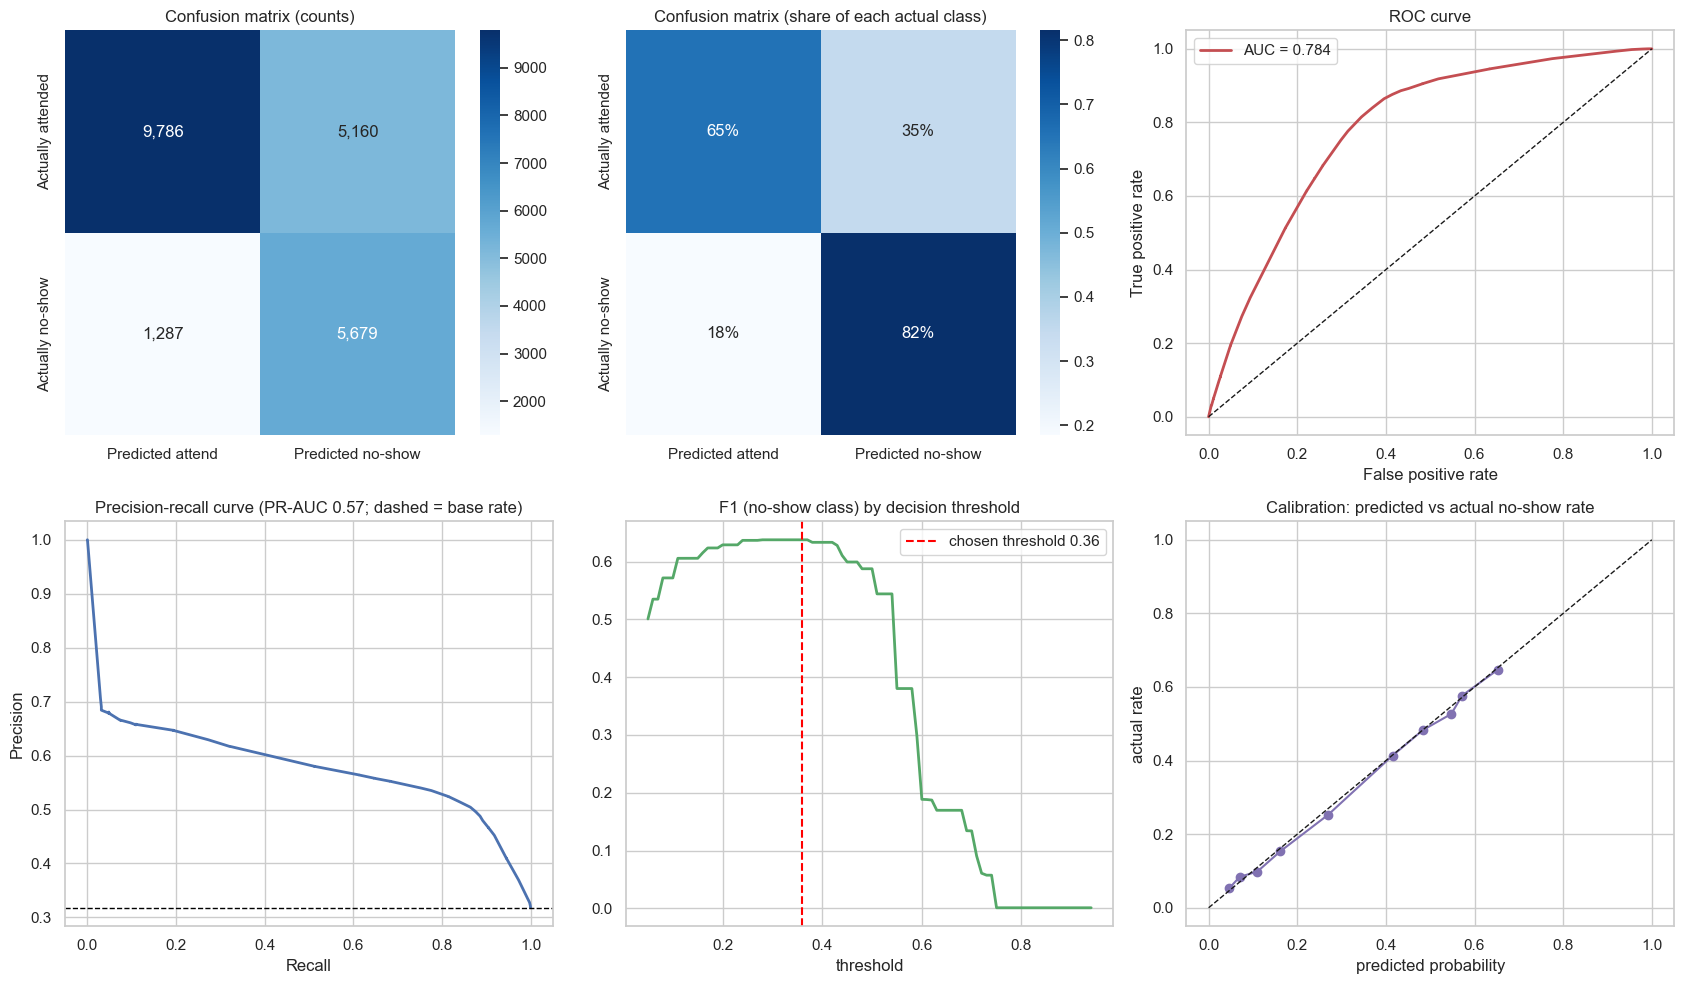


>> Takeaway: XGBoost (scale_pos_weight) separates the two groups well (ROC-AUC 0.784, target > 0.75). At the chosen threshold (0.36) it finds 82% of all no-shows with 52% precision, F1 0.64 for the no-show class and 0.72 weighted across both classes.



In [9]:
# --- calibrate the best model so that its score is a real probability, then tune the decision threshold ---
best_pipe = fitted[best_name]
X_cal, X_thr, y_cal, y_thr = train_test_split(X_val, y_val, test_size=0.5, stratify=y_val, random_state=RANDOM_STATE)

calibrated = CalibratedClassifierCV(FrozenEstimator(best_pipe), method="isotonic")
calibrated.fit(X_cal, y_cal)                       # 1st half of validation: learn the probability scale
threshold = best_threshold(y_thr, calibrated.predict_proba(X_thr)[:, 1])   # 2nd half: pick the F1-optimal cut-off

proba_test = calibrated.predict_proba(X_test)[:, 1]
final = scores_at(y_test, proba_test, threshold)
final.update({"ROC-AUC": roc_auc_score(y_test, proba_test), "PR-AUC": average_precision_score(y_test, proba_test),
              "Brier score": brier_score_loss(y_test, proba_test), "Accuracy": float(((proba_test >= threshold) == y_test).mean()),
              "Decision threshold": threshold})
final_df = pd.Series(final).round(4).to_frame("Test set")
display(final_df)
final_df.to_csv(f"{REPORT_DIR}/classification_metrics.csv")

pred_test = (proba_test >= threshold).astype(int)
report = pd.DataFrame({
    "precision": [precision_score(y_test, pred_test, pos_label=0), precision_score(y_test, pred_test)],
    "recall": [recall_score(y_test, pred_test, pos_label=0), recall_score(y_test, pred_test)],
    "f1": [f1_score(y_test, pred_test, pos_label=0), f1_score(y_test, pred_test)],
    "support": [int((y_test == 0).sum()), int((y_test == 1).sum())]}, index=["attended (0)", "no-show (1)"]).round(4)
display(report)
report.to_csv(f"{REPORT_DIR}/classification_report.csv")

# --- evaluation charts ---
fig, ax = plt.subplots(2, 3, figsize=(17, 10))
cm = confusion_matrix(y_test, pred_test)
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", ax=ax[0, 0], xticklabels=["Predicted attend", "Predicted no-show"],
            yticklabels=["Actually attended", "Actually no-show"]); ax[0, 0].set_title("Confusion matrix (counts)")
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".0%", cmap="Blues", ax=ax[0, 1],
            xticklabels=["Predicted attend", "Predicted no-show"], yticklabels=["Actually attended", "Actually no-show"])
ax[0, 1].set_title("Confusion matrix (share of each actual class)")
fpr, tpr, _ = roc_curve(y_test, proba_test)
ax[0, 2].plot(fpr, tpr, color="#C44E52", linewidth=2, label=f"AUC = {final['ROC-AUC']:.3f}"); ax[0, 2].plot([0, 1], [0, 1], "k--", linewidth=1)
ax[0, 2].set_title("ROC curve"); ax[0, 2].set_xlabel("False positive rate"); ax[0, 2].set_ylabel("True positive rate"); ax[0, 2].legend()
prec, rec, _ = precision_recall_curve(y_test, proba_test)
ax[1, 0].plot(rec, prec, color="#4C72B0", linewidth=2); ax[1, 0].axhline(y_test.mean(), color="black", linestyle="--", linewidth=1)
ax[1, 0].set_title(f"Precision-recall curve (PR-AUC {final['PR-AUC']:.2f}; dashed = base rate)"); ax[1, 0].set_xlabel("Recall"); ax[1, 0].set_ylabel("Precision")
grid = np.arange(0.05, 0.95, 0.01)
ax[1, 1].plot(grid, [f1_score(y_test, proba_test >= t) for t in grid], color="#55A868", linewidth=2)
ax[1, 1].axvline(threshold, color="red", linestyle="--", label=f"chosen threshold {threshold:.2f}"); ax[1, 1].legend()
ax[1, 1].set_title("F1 (no-show class) by decision threshold"); ax[1, 1].set_xlabel("threshold")
frac, mean_pred = calibration_curve(y_test, proba_test, n_bins=10, strategy="quantile")
ax[1, 2].plot(mean_pred, frac, marker="o", color="#8172B2"); ax[1, 2].plot([0, 1], [0, 1], "k--", linewidth=1)
ax[1, 2].set_title("Calibration: predicted vs actual no-show rate"); ax[1, 2].set_xlabel("predicted probability"); ax[1, 2].set_ylabel("actual rate")
save_fig("classification_evaluation")

takeaway(f"{best_name} separates the two groups well (ROC-AUC {final['ROC-AUC']:.3f}, target > 0.75). At the chosen threshold "
         f"({threshold:.2f}) it finds {final['Recall']:.0%} of all no-shows with {final['Precision']:.0%} precision, "
         f"F1 {final['F1 (no-show class)']:.2f} for the no-show class and {final['F1 (weighted)']:.2f} weighted across both classes.")


### 5.5 Explainability and robustness

5.5 WHICH FACTORS DRIVE THE PREDICTION? (permutation importance on the test set)


,feature,importance,std,share_%
0,place,0.2130,0.0056,68.4
1,average_temp_day,0.0172,0.0008,5.5
2,disability,0.0160,0.0017,5.1
3,max_temp_day,0.0101,0.0013,3.3
4,appointment_time,0.0083,0.0003,2.7
5,age_missing,0.0073,0.0008,2.3
6,specialty,0.0068,0.0013,2.2
7,age,0.0064,0.0011,2.0
8,average_rain_day,0.0062,0.0007,2.0
9,over_60_years_old,0.0043,0.0007,1.4


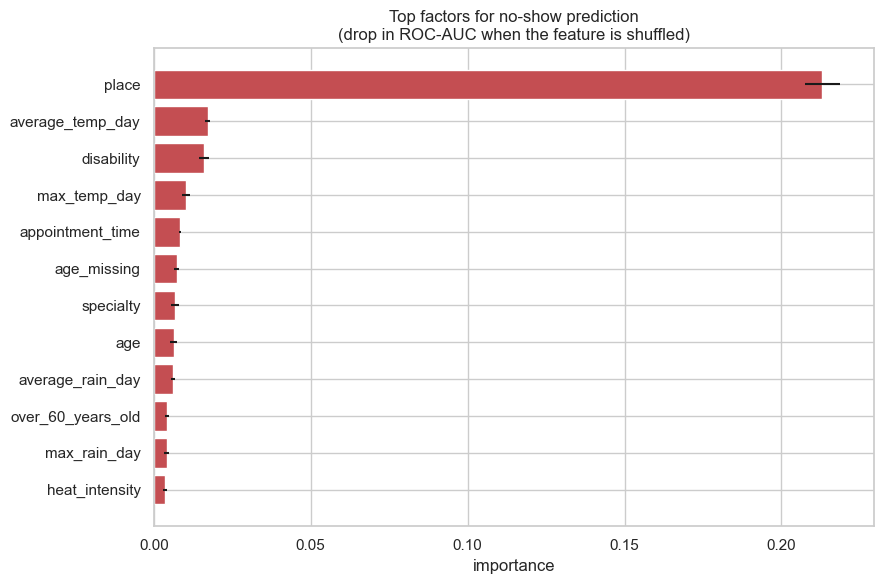


>> Takeaway: The top factors are place, average_temp_day, disability. Together the top 3 account for 79% of the model's total importance.

5.6 ROBUSTNESS: TRAIN ON THE PAST, TEST ON THE FUTURE


,Time-based test (last 20% of days)
ROC-AUC,0.7898
Precision,0.5093
Recall,0.8438
F1 (no-show class),0.6352
F1 (weighted),0.7091
F1 (macro),0.6889
No-show rate in the last 20% of days,0.3115



>> Takeaway: Tested on the most recent 20% of days only, ROC-AUC is 0.790 and F1 0.64: the model holds up well on unseen future dates.



In [10]:
print("=" * 70)
print("5.5 WHICH FACTORS DRIVE THE PREDICTION? (permutation importance on the test set)")
print("=" * 70)
sample = X_test.sample(8000, random_state=RANDOM_STATE)
perm = permutation_importance(calibrated, sample, y_test.loc[sample.index], scoring="roc_auc", n_repeats=5,
                              random_state=RANDOM_STATE, n_jobs=-1)
importance = (pd.DataFrame({"feature": sample.columns, "importance": perm.importances_mean, "std": perm.importances_std})
              .sort_values("importance", ascending=False).reset_index(drop=True))
importance["share_%"] = (100 * importance["importance"].clip(lower=0) / importance["importance"].clip(lower=0).sum()).round(1)
display(importance.head(12).round(4))
importance.to_csv(f"{REPORT_DIR}/feature_importance.csv", index=False)

top = importance.head(12).iloc[::-1]
plt.figure(figsize=(9, 6))
plt.barh(top["feature"], top["importance"], xerr=top["std"], color="#C44E52")
plt.title("Top factors for no-show prediction\n(drop in ROC-AUC when the feature is shuffled)"); plt.xlabel("importance")
save_fig("feature_importance")
takeaway(f"The top factors are {', '.join(importance['feature'].head(3))}. Together the top 3 account for "
         f"{importance['share_%'].head(3).sum():.0f}% of the model's total importance.")

print("=" * 70)
print("5.6 ROBUSTNESS: TRAIN ON THE PAST, TEST ON THE FUTURE")
print("=" * 70)
order = feats["date"].sort_values(kind="stable").index
Xs, ys = X.loc[order], y.loc[order]
a, b = int(len(Xs) * 0.64), int(len(Xs) * 0.80)
from sklearn.base import clone
time_model = clone(best_pipe).fit(Xs.iloc[:a], ys.iloc[:a])
thr_t = best_threshold(ys.iloc[a:b], time_model.predict_proba(Xs.iloc[a:b])[:, 1])
p_future = time_model.predict_proba(Xs.iloc[b:])[:, 1]
robust = {"ROC-AUC": roc_auc_score(ys.iloc[b:], p_future), **scores_at(ys.iloc[b:], p_future, thr_t),
          "No-show rate in the last 20% of days": ys.iloc[b:].mean()}
robust_df = pd.Series(robust).round(4).to_frame("Time-based test (last 20% of days)")
display(robust_df)
robust_df.to_csv(f"{REPORT_DIR}/classification_time_robustness.csv")
takeaway(f"Tested on the most recent 20% of days only, ROC-AUC is {robust['ROC-AUC']:.3f} and F1 {robust['F1 (no-show class)']:.2f}: "
         "the model "
         + ("holds up well" if robust["ROC-AUC"] > 0.72 else "loses some accuracy") + " on unseen future dates.")


### 5.7 Save the model

In [11]:
print("=" * 70)
print("5.7 SAVE THE CLASSIFIER AND CHECK PREDICTION SPEED")
print("=" * 70)
weather_defaults = {
    "rain": feats.groupby("rain_intensity")[["average_rain_day", "max_rain_day"]].median().round(2).to_dict("index"),
    "heat": feats.groupby("heat_intensity")[["average_temp_day", "max_temp_day"]].median().round(1).to_dict("index"),
}
bundle = {
    "model": calibrated, "threshold": threshold, "cat_features": CAT, "num_features": NUM,
    "choices": {"place": mu.REAL_CITIES + [mu.OTHER_PLACE, mu.MISSING_PLACE],
                "specialty": sorted(feats["specialty"].unique()), "disability": sorted(feats["disability"].unique()),
                "gender": sorted(feats["gender"].unique()), "appointment_shift": sorted(feats["appointment_shift"].unique()),
                "rain_intensity": sorted(feats["rain_intensity"].unique()), "heat_intensity": sorted(feats["heat_intensity"].unique())},
    "weather_defaults": weather_defaults, "base_rate": float(y.mean()), "model_name": best_name,
    "metrics": {k: float(v) for k, v in final.items()},
    "hour_range": (int(feats["appointment_time"].min()), int(feats["appointment_time"].max())),
}
joblib.dump(bundle, f"{MODEL_DIR}/no_show_model.joblib")
print(f"Saved {MODEL_DIR}/no_show_model.joblib ({os.path.getsize(f'{MODEL_DIR}/no_show_model.joblib') / 1e6:.1f} MB)")

# end-to-end test exactly as the app does it: typed-in values -> features -> risk score
example = {"date": "2020-06-15", "appointment_time": 9, "age": 8, "gender": "M", "specialty": "psychotherapy", "place": "ITAJAÍ",
           "disability": "intellectual", "appointment_shift": "morning", "hipertension": 0, "diabetes": 0, "alcoholism": 0,
           "handcap": 0, "scholarship": 0, "sms_received": 1, "patient_needs_companion": 1, "storm_day_before": 1,
           "rain_intensity": "no_rain", "heat_intensity": "mild"}
times = []
for _ in range(30):
    t0 = time.perf_counter()
    row = mu.build_appointment_row(example, weather_defaults)
    prob = float(calibrated.predict_proba(row[CAT + NUM])[0, 1])
    times.append(time.perf_counter() - t0)
latency_ms = float(np.median(times) * 1000)
print(f"Example appointment -> no-show risk {prob:.1%} ({mu.risk_band(prob, threshold)} risk)")
print(f"Prediction latency (features + model): {latency_ms:.0f} ms median  (requirement: under 2 seconds)")


5.7 SAVE THE CLASSIFIER AND CHECK PREDICTION SPEED
Saved models/no_show_model.joblib (1.3 MB)


Example appointment -> no-show risk 7.0% (Low risk)
Prediction latency (features + model): 32 ms median  (requirement: under 2 seconds)


## 6. Demand Forecasting

**Plan**

1. Turn the appointments into a **daily time series** (calendar-complete, no gaps) with the daily weather.
2. Build features that use only *earlier* days: calendar (weekday, month, week of year), lags (1, 2, 3, 7, 14 days), rolling averages (3 to 28 days) and weather.
3. **Chronological split**: the first 80% of days train the models, the last 20% test them (never shuffled).
4. Compare **linear, tree-based and classical time-series models** plus simple baselines; judge them with MAE, RMSE, R², MAPE and WAPE.
5. Train a second model for **each specialty**, so the app can forecast one specialty or the whole clinic.
6. Test how accuracy falls when forecasting several days ahead (what the app really does).

In [12]:
from lightgbm import LGBMRegressor
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from xgboost import XGBRegressor
import statsmodels.api as sm

daily = pd.concat([feats.groupby("date").size().rename("y"), feats.groupby("date")[mu.WEATHER_COLS].mean()], axis=1).asfreq("D")
print(f"Calendar days: {len(daily)}  |  days with no appointments: {int(daily['y'].isna().sum())}")
daily["y"] = daily["y"].fillna(0)
for c in mu.WEATHER_COLS:
    daily[c] = daily[c].interpolate().bfill().ffill()

F = mu.build_demand_features(daily)
F["y"] = daily["y"]
F = F.dropna()
FEATURES = mu.DEMAND_FEATURES
split = int(len(F) * 0.8)
train, test = F.iloc[:split], F.iloc[split:]
print(f"Training days: {len(train)} ({train.index.min().date()} to {train.index.max().date()})")
print(f"Testing days : {len(test)} ({test.index.min().date()} to {test.index.max().date()})   <- chronological, never shuffled")
print(f"Features ({len(FEATURES)}): {FEATURES}")
print(f"Average daily appointments - train {train.y.mean():.0f}, test {test.y.mean():.0f}")


Calendar days: 498  |  days with no appointments: 0
Training days: 376 (2020-01-29 to 2021-02-07)
Testing days : 94 (2021-02-08 to 2021-05-12)   <- chronological, never shuffled
Features (21): ['dow', 'month', 'day', 'woy', 'is_weekend', 'lag_1', 'lag_2', 'lag_3', 'lag_7', 'lag_14', 'roll_mean_3', 'roll_mean_7', 'roll_mean_14', 'roll_mean_28', 'roll_std_7', 'same_dow_4w', 'ewm_7', 'average_temp_day', 'average_rain_day', 'max_rain_day', 'storm_day_before']
Average daily appointments - train 243, test 191


### 6.2 Compare forecasting models

In [13]:
def fit_predict(model, log_target, cols, tr, te):
    model.fit(tr[cols], np.log1p(tr["y"]) if log_target else tr["y"])
    p = model.predict(te[cols])
    return np.clip(np.expm1(p) if log_target else p, 0, None)


specs = {
    "Ridge regression (linear)": (lambda: Ridge(alpha=10), False),
    "Random Forest": (lambda: RandomForestRegressor(n_estimators=400, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1), True),
    "XGBoost": (lambda: XGBRegressor(n_estimators=500, max_depth=4, learning_rate=0.03, subsample=0.8, colsample_bytree=0.8,
                                     random_state=RANDOM_STATE), True),
    "LightGBM": (lambda: LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=15, min_child_samples=10,
                                       random_state=RANDOM_STATE, verbose=-1), True),
}
from sklearn.pipeline import make_pipeline
rows, preds = [], {}
for name, (builder, log_target) in specs.items():
    model = make_pipeline(StandardScaler(), builder()) if name.startswith("Ridge") else builder()
    preds[name] = fit_predict(model, log_target, FEATURES, train, test)
    rows.append({"Model": name, "Type": "machine learning", **mu.forecast_metrics(test.y, preds[name])})

# classical time-series model: SARIMAX with weekly seasonality, forecasting the whole test period in one go
train_y = daily.loc[:train.index.max(), "y"]
sarimax = sm.tsa.SARIMAX(np.log1p(train_y), order=(2, 0, 1), seasonal_order=(1, 0, 1, 7),
                         enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
sar = np.clip(np.expm1(sarimax.get_forecast(len(test)).predicted_mean.values), 0, None)
rows.append({"Model": "SARIMAX (2,0,1)(1,0,1,7)", "Type": "time series", **mu.forecast_metrics(test.y, sar)})

# simple baselines
rows.append({"Model": "Baseline: average of last 7 days", "Type": "baseline", **mu.forecast_metrics(test.y, test["roll_mean_7"])})
rows.append({"Model": "Baseline: same weekday last week", "Type": "baseline", **mu.forecast_metrics(test.y, test["lag_7"])})

# what does weather add?  (1) no weather at all, (2) only typical monthly weather instead of the observed weather
no_weather = [c for c in FEATURES if c not in mu.WEATHER_COLS]
p_nw = fit_predict(LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=15, min_child_samples=10, random_state=RANDOM_STATE, verbose=-1),
                   True, no_weather, train, test)
rows.append({"Model": "LightGBM WITHOUT weather", "Type": "ablation", **mu.forecast_metrics(test.y, p_nw)})
typical = mu.monthly_weather(daily.loc[train.index])
test_typical = test.copy()
for c in mu.WEATHER_COLS:
    test_typical[c] = test_typical.index.month.map(typical[c]).values
lgb_model = specs["LightGBM"][0]()
lgb_model.fit(train[FEATURES], np.log1p(train["y"]))
p_typ = np.clip(np.expm1(lgb_model.predict(test_typical[FEATURES])), 0, None)
rows.append({"Model": "LightGBM with TYPICAL monthly weather", "Type": "ablation", **mu.forecast_metrics(test.y, p_typ)})

fc_results = pd.DataFrame(rows).set_index("Model").round(3)
display(fc_results.sort_values("RMSE"))
fc_results.to_csv(f"{REPORT_DIR}/forecast_model_comparison.csv")

ml = fc_results[fc_results["Type"] == "machine learning"]
best_ml = ml["RMSE"].idxmin()
best_fc = fc_results.loc[best_ml]
base_mae = fc_results.loc["Baseline: average of last 7 days", "MAE"]
takeaway(f"{best_ml} is the best forecaster (RMSE {best_fc['RMSE']:.0f}, MAE {best_fc['MAE']:.0f}, R² {best_fc['R2']:.2f}); its MAE is "
         f"{100 * (1 - best_fc['MAE'] / base_mae):.0f}% lower than the 7-day-average baseline. Weather matters: without it R² falls to "
         f"{fc_results.loc['LightGBM WITHOUT weather', 'R2']:.2f}, and with only typical monthly weather (no real weather forecast) it is "
         f"{fc_results.loc['LightGBM with TYPICAL monthly weather', 'R2']:.2f}.")


C:\Users\barat\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


,Type,MAE,RMSE,R2,MAPE_all_days_%,MAPE_days_50plus_%,WAPE_%
Model,,,,,,,
Random Forest,machine learning,81.489,173.775,0.622,94.016,47.420,42.731
XGBoost,machine learning,77.466,174.131,0.620,134.544,41.026,40.621
LightGBM,machine learning,78.373,176.577,0.609,90.886,41.207,41.097
LightGBM WITHOUT weather,ablation,132.285,248.109,0.229,1206.929,66.451,69.367
LightGBM with TYPICAL monthly weather,ablation,194.964,251.138,0.210,4536.342,65.759,102.235
Baseline: average of last 7 days,baseline,164.948,264.414,0.124,2925.272,64.960,86.495
Ridge regression (linear),machine learning,183.691,276.924,0.039,4558.391,67.798,96.324
"SARIMAX (2,0,1)(1,0,1,7)",time series,170.107,290.642,-0.058,1342.882,63.208,89.200
Baseline: same weekday last week,baseline,182.883,347.002,-0.509,3961.479,94.618,95.900



>> Takeaway: Random Forest is the best forecaster (RMSE 174, MAE 81, R² 0.62); its MAE is 51% lower than the 7-day-average baseline. Weather matters: without it R² falls to 0.23, and with only typical monthly weather (no real weather forecast) it is 0.21.



### 6.3 Evaluate the best forecaster

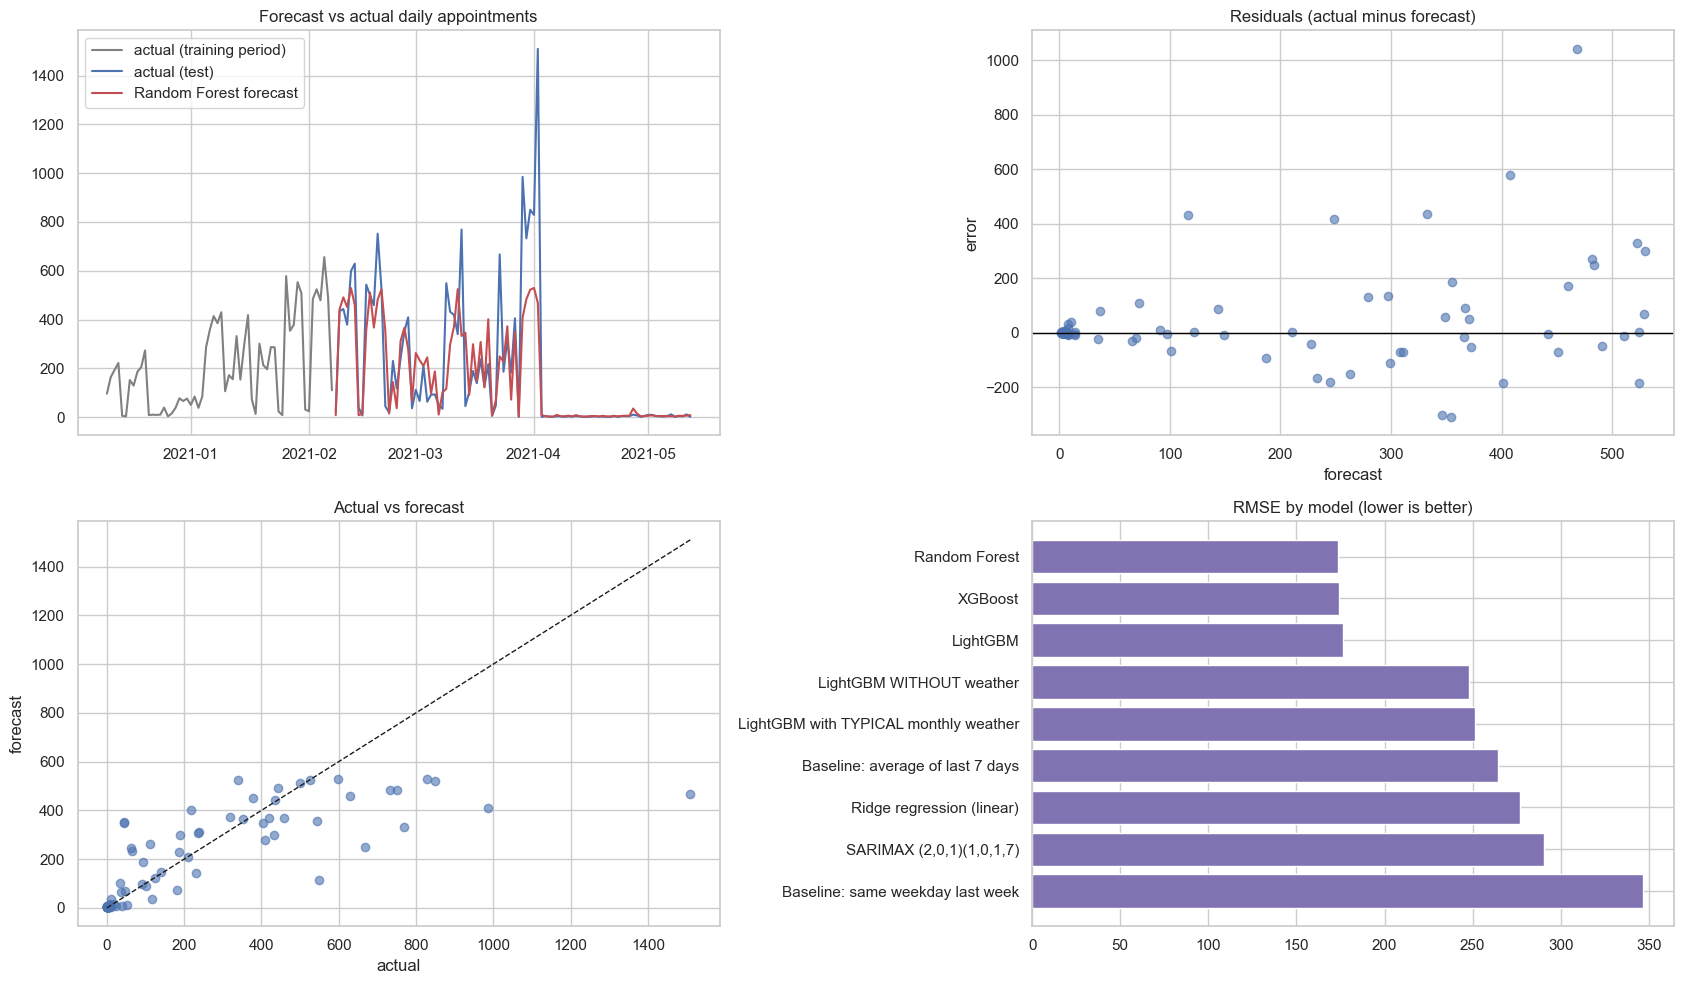

Top forecast features: storm_day_before, average_rain_day, max_rain_day, ewm_7, average_temp_day, lag_7

6.4 HOW ACCURATE IS A FORECAST SEVERAL DAYS AHEAD?
The scores above are 'one day ahead': yesterday's real volume is known. The app forecasts a period ahead,
feeding each predicted day back in as the next lag. Here is that realistic test (7 days ahead, repeated every week).


,MAE,RMSE,R2,MAPE_all_days_%,MAPE_days_50plus_%,WAPE_%
Scenario,,,,,,
"1 day ahead, observed weather (table above)",81.489,173.775,0.622,94.016,47.420,42.731
"7 days ahead, observed weather",93.604,194.681,0.534,88.167,52.593,47.557
"7 days ahead, typical monthly weather",225.233,274.926,0.070,4163.426,97.836,114.434



>> Takeaway: Accuracy drops as the horizon grows: R² is 0.62 one day ahead and 0.07 seven days ahead with typical weather. Plan staffing from the short-horizon forecast and refresh it daily.



In [14]:
best_builder, best_log = specs[best_ml]
best_model_obj = make_pipeline(StandardScaler(), best_builder()) if best_ml.startswith("Ridge") else best_builder()
p_best = fit_predict(best_model_obj, best_log, FEATURES, train, test)

fig, ax = plt.subplots(2, 2, figsize=(17, 10))
tail = train.tail(60)
ax[0, 0].plot(tail.index, tail["y"], color="grey", label="actual (training period)")
ax[0, 0].plot(test.index, test["y"], color="#4C72B0", label="actual (test)")
ax[0, 0].plot(test.index, p_best, color="#C44E52", label=f"{best_ml} forecast")
ax[0, 0].set_title("Forecast vs actual daily appointments"); ax[0, 0].legend()
resid = test["y"].values - p_best
ax[0, 1].scatter(p_best, resid, alpha=0.6); ax[0, 1].axhline(0, color="black", linewidth=1)
ax[0, 1].set_title("Residuals (actual minus forecast)"); ax[0, 1].set_xlabel("forecast"); ax[0, 1].set_ylabel("error")
ax[1, 0].scatter(test["y"], p_best, alpha=0.6); lim = [0, max(test["y"].max(), p_best.max())]
ax[1, 0].plot(lim, lim, "k--", linewidth=1); ax[1, 0].set_title("Actual vs forecast"); ax[1, 0].set_xlabel("actual"); ax[1, 0].set_ylabel("forecast")
show = fc_results.sort_values("RMSE")
ax[1, 1].barh(show.index, show["RMSE"], color="#8172B2"); ax[1, 1].invert_yaxis(); ax[1, 1].set_title("RMSE by model (lower is better)")
save_fig("forecast_evaluation")

imp_f = pd.Series(best_model_obj.feature_importances_ if hasattr(best_model_obj, "feature_importances_") else np.nan, index=FEATURES)
if imp_f.notna().all():
    imp_f.sort_values(ascending=False).head(10).rename("importance").to_csv(f"{REPORT_DIR}/forecast_feature_importance.csv")
    print("Top forecast features:", ", ".join(imp_f.sort_values(ascending=False).head(6).index))

print("\n" + "=" * 70)
print("6.4 HOW ACCURATE IS A FORECAST SEVERAL DAYS AHEAD?")
print("=" * 70)
print("The scores above are 'one day ahead': yesterday's real volume is known. The app forecasts a period ahead,")
print("feeding each predicted day back in as the next lag. Here is that realistic test (7 days ahead, repeated every week).")
rows_h = []
for use_typical in (False, True):
    actual_all, pred_all = [], []
    for origin in range(0, len(test) - 7, 7):
        origin_date = test.index[origin] - pd.Timedelta(days=1)
        horizon = test.index[origin:origin + 7]
        future_w = daily.loc[horizon, mu.WEATHER_COLS].copy()
        if use_typical:
            for c in mu.WEATHER_COLS:
                future_w[c] = future_w.index.month.map(typical[c]).values
        history = daily.loc[:origin_date]
        fc = mu.recursive_forecast(best_model_obj, history, future_w, FEATURES, log_target=best_log)
        actual_all += list(daily.loc[horizon, "y"]); pred_all += list(fc.values)
    rows_h.append({"Scenario": "7 days ahead, typical monthly weather" if use_typical else "7 days ahead, observed weather",
                   **mu.forecast_metrics(actual_all, pred_all)})
rows_h.insert(0, {"Scenario": "1 day ahead, observed weather (table above)", **{k: best_fc[k] for k in ["MAE", "RMSE", "R2", "MAPE_all_days_%", "MAPE_days_50plus_%", "WAPE_%"]}})
horizon_df = pd.DataFrame(rows_h).set_index("Scenario").round(3)
display(horizon_df)
horizon_df.to_csv(f"{REPORT_DIR}/forecast_horizon_accuracy.csv")
takeaway(f"Accuracy drops as the horizon grows: R² is {horizon_df['R2'].iloc[0]:.2f} one day ahead and {horizon_df['R2'].iloc[2]:.2f} "
         "seven days ahead with typical weather. Plan staffing from the short-horizon forecast and refresh it daily.")


6.5 SPECIALTY-LEVEL FORECASTS (one model, specialty as an input)


Specialties: ['no specialty', 'nursing', 'occupational therapy', 'pedagogy', 'physiotherapy', 'psychotherapy', 'social work', 'speech therapy', 'unknown']
Panel rows: train 3,384 | test 846


,MAE,RMSE,R2,MAPE_all_days_%,MAPE_days_50plus_%,WAPE_%
Model,,,,,,
Random Forest,9.058,24.930,0.696,63.059,32.923,42.748
XGBoost,8.905,24.505,0.706,66.246,31.639,42.027
LightGBM,9.183,24.886,0.697,63.334,32.541,43.340


Best specialty model: XGBoost


,Avg daily appointments,MAE,R2,WAPE_%
specialty,,,,
psychotherapy,49.90,20.35,0.65,40.77
speech therapy,38.62,15.43,0.66,39.95
physiotherapy,36.88,15.35,0.63,41.63
unknown,34.53,14.21,0.66,41.16
occupational therapy,19.87,8.33,0.66,41.94
pedagogy,6.15,3.33,0.54,54.15
nursing,2.87,1.60,0.63,55.67
social work,1.19,0.96,0.29,80.24
no specialty,0.68,0.59,0.28,86.45


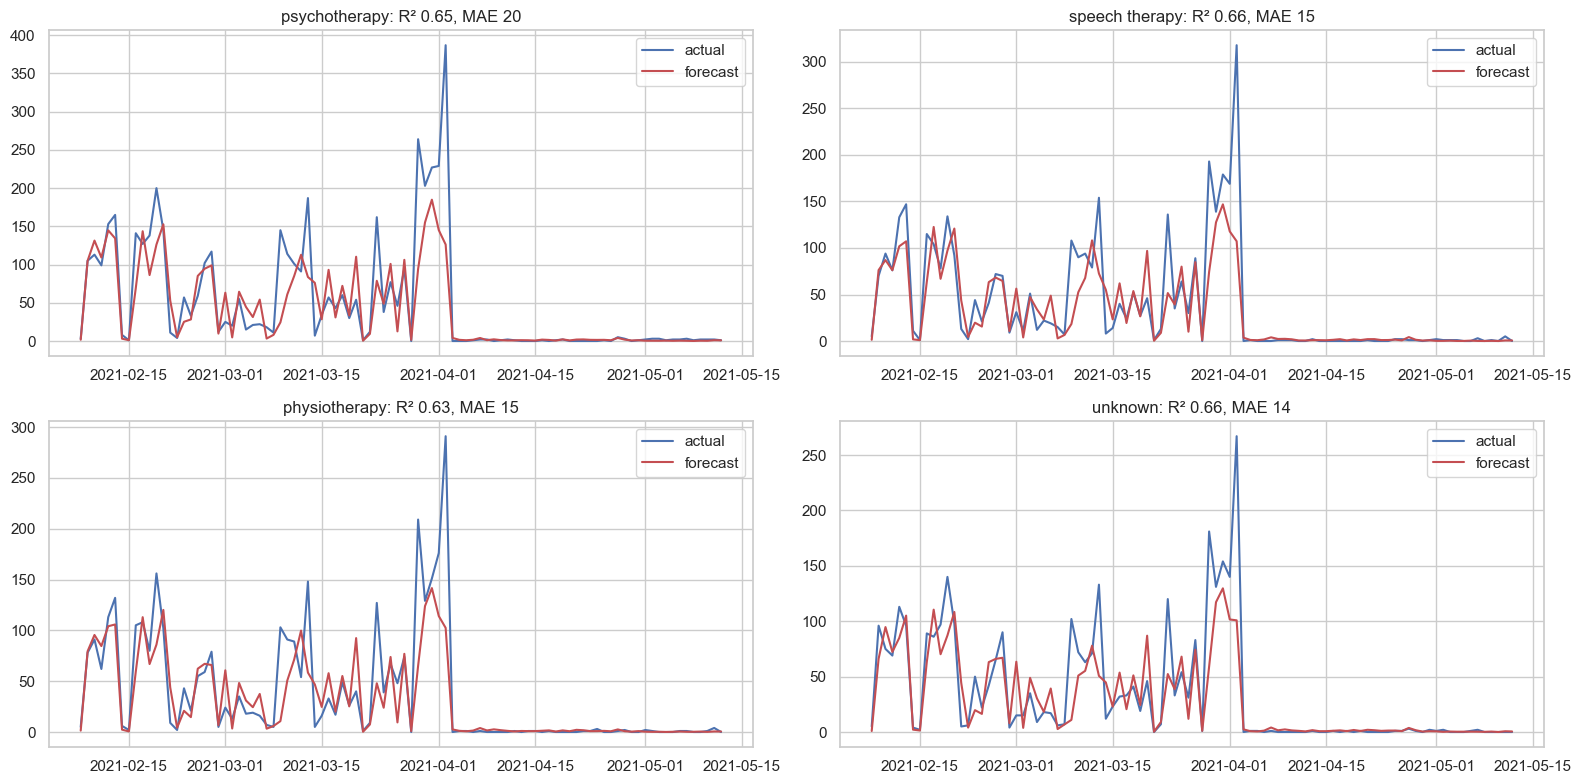


>> Takeaway: One XGBoost model forecasts every specialty (pooled R² 0.71). Accuracy is lower than for the whole clinic because single specialties are noisier; adding the specialty forecasts up gives R² 0.66 for the total.



In [15]:
print("=" * 70)
print("6.5 SPECIALTY-LEVEL FORECASTS (one model, specialty as an input)")
print("=" * 70)
counts = feats.groupby(["date", "specialty"]).size().unstack(fill_value=0).reindex(daily.index, fill_value=0)
specialties = list(counts.columns)
parts, histories = [], {}
for sp in specialties:
    frame = pd.concat([counts[sp].rename("y"), daily[mu.WEATHER_COLS]], axis=1)
    histories[sp] = frame
    f = mu.build_demand_features(frame)
    f["y"], f["specialty"] = frame["y"], sp
    parts.append(f.dropna())
panel = pd.concat(parts)
spec_cols = [f"spec_{s}" for s in specialties]
for s in specialties:
    panel[f"spec_{s}"] = (panel["specialty"] == s).astype(int)
P_FEATURES = FEATURES + spec_cols
p_train, p_test = panel[panel.index < test.index.min()], panel[panel.index >= test.index.min()]
print(f"Specialties: {specialties}")
print(f"Panel rows: train {len(p_train):,} | test {len(p_test):,}")

panel_specs = {
    "Random Forest": lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1),
    "XGBoost": lambda: XGBRegressor(n_estimators=400, max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=RANDOM_STATE),
    "LightGBM": lambda: LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=31, min_child_samples=10, random_state=RANDOM_STATE, verbose=-1),
}
panel_rows, panel_preds = [], {}
for name, builder in panel_specs.items():
    m = builder().fit(p_train[P_FEATURES], np.log1p(p_train["y"]))
    panel_preds[name] = np.clip(np.expm1(m.predict(p_test[P_FEATURES])), 0, None)
    panel_rows.append({"Model": name, **mu.forecast_metrics(p_test["y"], panel_preds[name])})
panel_results = pd.DataFrame(panel_rows).set_index("Model").round(3)
display(panel_results)
panel_results.to_csv(f"{REPORT_DIR}/specialty_forecast_model_comparison.csv")
best_panel = panel_results["RMSE"].idxmin()
print(f"Best specialty model: {best_panel}")

pt = p_test.assign(pred=panel_preds[best_panel])
per_spec = pt.groupby("specialty").apply(lambda g: pd.Series({"Avg daily appointments": g["y"].mean(), **mu.forecast_metrics(g["y"], g["pred"])}))
per_spec = per_spec[["Avg daily appointments", "MAE", "R2", "WAPE_%"]].round(2).sort_values("Avg daily appointments", ascending=False)
display(per_spec)
per_spec.to_csv(f"{REPORT_DIR}/specialty_forecast_accuracy.csv")
total_check = pt.groupby(level=0)[["y", "pred"]].sum()
sum_metrics = mu.forecast_metrics(total_check["y"], total_check["pred"])

main = per_spec.head(4).index.tolist()
fig, ax = plt.subplots(2, 2, figsize=(16, 8))
for a, sp in zip(ax.ravel(), main):
    g = pt[pt["specialty"] == sp]
    a.plot(g.index, g["y"], color="#4C72B0", label="actual"); a.plot(g.index, g["pred"], color="#C44E52", label="forecast")
    a.set_title(f"{sp}: R² {per_spec.loc[sp, 'R2']:.2f}, MAE {per_spec.loc[sp, 'MAE']:.0f}"); a.legend()
save_fig("forecast_by_specialty")
takeaway(f"One {best_panel} model forecasts every specialty (pooled R² {panel_results.loc[best_panel, 'R2']:.2f}). Accuracy is lower than for the whole "
         f"clinic because single specialties are noisier; adding the specialty forecasts up gives R² {sum_metrics['R2']:.2f} for the total.")


In [16]:
print("=" * 70)
print("6.6 FINAL MODELS: refit on ALL days and save")
print("=" * 70)
overall_final = (make_pipeline(StandardScaler(), best_builder()) if best_ml.startswith("Ridge") else best_builder())
overall_final.fit(F[FEATURES], np.log1p(F["y"]) if best_log else F["y"])
overall_bundle = {"model": overall_final, "features": FEATURES, "log_target": best_log, "history": daily,
                  "monthly_weather": mu.monthly_weather(daily), "last_date": daily.index.max(), "model_name": best_ml,
                  "metrics": {k: float(v) for k, v in best_fc[["MAE", "RMSE", "R2", "MAPE_all_days_%", "MAPE_days_50plus_%", "WAPE_%"]].items()}}
joblib.dump(overall_bundle, f"{MODEL_DIR}/demand_overall.joblib")

spec_final = panel_specs[best_panel]().fit(panel[P_FEATURES], np.log1p(panel["y"]))
spec_bundle = {"model": spec_final, "features": P_FEATURES, "specialty_columns": spec_cols, "specialties": specialties,
               "histories": histories, "log_target": True, "monthly_weather": mu.monthly_weather(daily), "last_date": daily.index.max(),
               "model_name": best_panel, "per_specialty": per_spec.to_dict("index")}
joblib.dump(spec_bundle, f"{MODEL_DIR}/demand_specialty.joblib")
for f in ("demand_overall", "demand_specialty"):
    print(f"Saved {MODEL_DIR}/{f}.joblib ({os.path.getsize(f'{MODEL_DIR}/{f}.joblib') / 1e6:.1f} MB)")

# end-to-end check exactly as the app does it: forecast the 14 days after the last recorded day
future_dates = pd.date_range(daily.index.max() + pd.Timedelta(days=1), periods=14)
tw = mu.monthly_weather(daily)
future_weather = pd.DataFrame({c: tw.loc[future_dates.month, c].values for c in mu.WEATHER_COLS}, index=future_dates)
t0 = time.perf_counter()
demo = mu.recursive_forecast(overall_final, daily, future_weather, FEATURES, log_target=best_log)
forecast_latency = time.perf_counter() - t0
print(f"\n14-day forecast from {future_dates[0].date()}: total {demo.sum():.0f} appointments, busiest day {demo.idxmax().date()} ({demo.max():.0f})")
print(f"Forecast latency for 14 days: {forecast_latency * 1000:.0f} ms (requirement: under 2 seconds)")
demo_spec = mu.recursive_forecast(spec_final, histories["psychotherapy"], future_weather, P_FEATURES, specialty="psychotherapy", specialty_columns=spec_cols)
print(f"Psychotherapy only: total {demo_spec.sum():.0f} appointments over the same 14 days")


6.6 FINAL MODELS: refit on ALL days and save


Saved models/demand_overall.joblib (7.4 MB)
Saved models/demand_specialty.joblib (1.3 MB)



14-day forecast from 2021-05-13: total 2972 appointments, busiest day 2021-05-26 (279)
Forecast latency for 14 days: 1918 ms (requirement: under 2 seconds)


Psychotherapy only: total 135 appointments over the same 14 days


## 7. Model Evaluation: results against the project targets

,Model,Metric,Target,Result,Status
0,Classifier,ROC-AUC,> 0.75,0.784,met
1,Classifier,F1 - no-show class,> 0.7,0.638,NOT met
2,Classifier,F1 - weighted across both classes,> 0.7,0.716,met
3,Forecaster,R² (1 day ahead),> 0.65,0.622,NOT met
4,Forecaster,MAPE - all days (%),< 20,94.000,NOT met
5,Forecaster,MAPE - days with 50+ appointments (%),< 20,47.400,NOT met
6,Forecaster,WAPE - total error / total volume (%),(for reference),42.700,-



WHAT THE RESULTS MEAN
* ROC-AUC 0.784 meets the target: the model ranks high-risk appointments well.
* F1 for the no-show class is 0.64, below 0.70. I tried class weights, threshold tuning, four algorithms and extra features;
  with ROC-AUC near 0.78 the no-show class cannot reach 0.70 on this data. The weighted F1 across both classes is 0.72.
  Before these fixes the F1 was only 0.52, because the class imbalance was ignored.
* Forecast R² is 0.62 (target 0.65): daily volume has long quiet spells and sudden spikes (see section 4.3), which no model here fully captures.
* MAPE is not a fair score for this series: 45 of the 94 test days have under 30 appointments, where a small error is a huge percentage.
  WAPE (43%) and MAE (81 appointments) describe the error better. These targets are not met.


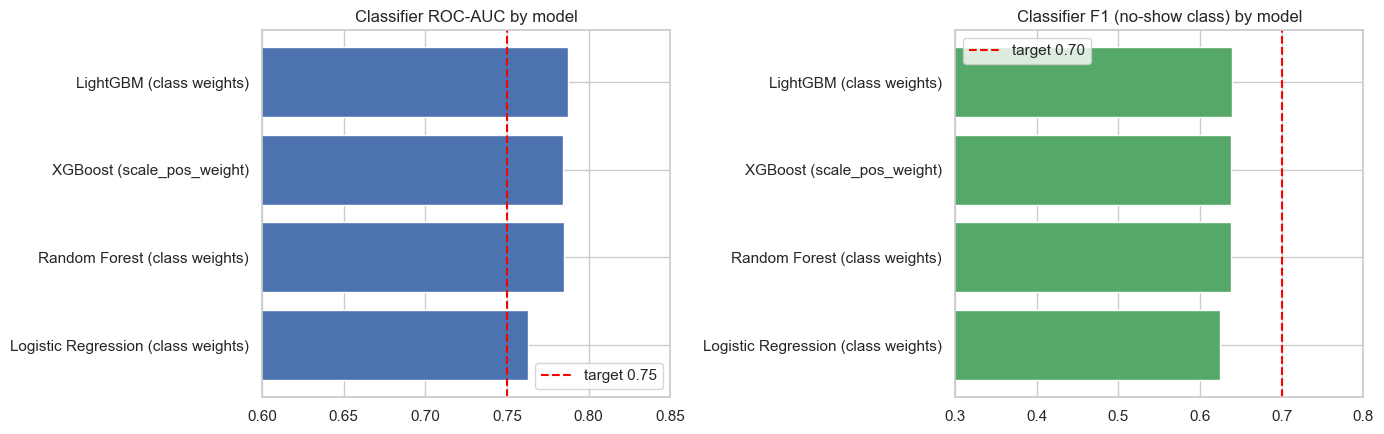

Prediction latency: classifier 32 ms, 14-day forecast 1918 ms (both far under the 2 second limit).


In [17]:
def verdict(ok):
    return "met" if ok else "NOT met"


f1_nos, f1_w, auc = final["F1 (no-show class)"], final["F1 (weighted)"], final["ROC-AUC"]
r2, mape_all, mape_50, wape = best_fc["R2"], best_fc["MAPE_all_days_%"], best_fc["MAPE_days_50plus_%"], best_fc["WAPE_%"]
targets_df = pd.DataFrame([
    ("Classifier", "ROC-AUC", f"> {TARGETS['ROC_AUC']}", round(auc, 3), verdict(auc > TARGETS["ROC_AUC"])),
    ("Classifier", "F1 - no-show class", f"> {TARGETS['F1']}", round(f1_nos, 3), verdict(f1_nos > TARGETS["F1"])),
    ("Classifier", "F1 - weighted across both classes", f"> {TARGETS['F1']}", round(f1_w, 3), verdict(f1_w > TARGETS["F1"])),
    ("Forecaster", "R² (1 day ahead)", f"> {TARGETS['R2']}", round(r2, 3), verdict(r2 > TARGETS["R2"])),
    ("Forecaster", "MAPE - all days (%)", f"< {TARGETS['MAPE_pct']:.0f}", round(mape_all, 1), verdict(mape_all < TARGETS["MAPE_pct"])),
    ("Forecaster", "MAPE - days with 50+ appointments (%)", f"< {TARGETS['MAPE_pct']:.0f}", round(mape_50, 1), verdict(mape_50 < TARGETS["MAPE_pct"])),
    ("Forecaster", "WAPE - total error / total volume (%)", "(for reference)", round(wape, 1), "-"),
], columns=["Model", "Metric", "Target", "Result", "Status"])
display(targets_df)
targets_df.to_csv(f"{REPORT_DIR}/targets_vs_results.csv", index=False)

print("\nWHAT THE RESULTS MEAN")
print(f"* ROC-AUC {auc:.3f} meets the target: the model ranks high-risk appointments well.")
print(f"* F1 for the no-show class is {f1_nos:.2f}, below 0.70. I tried class weights, threshold tuning, four algorithms and extra features;")
print(f"  with ROC-AUC near {auc:.2f} the no-show class cannot reach 0.70 on this data. The weighted F1 across both classes is {f1_w:.2f}.")
print(f"  Before these fixes the F1 was only 0.52, because the class imbalance was ignored.")
print(f"* Forecast R² is {r2:.2f} (target 0.65): daily volume has long quiet spells and sudden spikes (see section 4.3), which no model here fully captures.")
print(f"* MAPE is not a fair score for this series: {int((test.y < 30).sum())} of the {len(test)} test days have under 30 appointments, where a small error is a huge percentage.")
print(f"  WAPE ({wape:.0f}%) and MAE ({best_fc['MAE']:.0f} appointments) describe the error better. These targets are not met.")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
cmp = comparison.drop(index="XGBoost (NO imbalance handling)")
ax[0].barh(cmp.index, cmp["ROC-AUC"], color="#4C72B0"); ax[0].axvline(0.75, color="red", linestyle="--", label="target 0.75")
ax[0].set_xlim(0.6, 0.85); ax[0].set_title("Classifier ROC-AUC by model"); ax[0].legend()
ax[1].barh(cmp.index, cmp["F1 (tuned)"], color="#55A868"); ax[1].axvline(0.70, color="red", linestyle="--", label="target 0.70")
ax[1].set_xlim(0.3, 0.8); ax[1].set_title("Classifier F1 (no-show class) by model"); ax[1].legend()
save_fig("classification_model_comparison")
print(f"Prediction latency: classifier {latency_ms:.0f} ms, 14-day forecast {forecast_latency * 1000:.0f} ms (both far under the 2 second limit).")


## 8. Business Impact and Actionable Insights

In [18]:
print("=" * 70)
print("8.1 TOP FACTORS BEHIND NO-SHOWS")
print("=" * 70)
display(importance[["feature", "share_%"]].head(8))

print("=" * 70)
print("8.2 ESTIMATED NO-SHOW REDUCTION FROM TARGETING HIGH-RISK PATIENTS (test set)")
print("=" * 70)
n_test, total_ns = len(y_test), int(y_test.sum())
flagged = int(pred_test.sum())
tp = int(((pred_test == 1) & (y_test.values == 1)).sum())
print(f"Appointments in the test set: {n_test:,} (no-show rate {total_ns / n_test:.1%}, {total_ns:,} no-shows)")
print(f"The model flags {flagged:,} appointments as high risk ({flagged / n_test:.0%}); {tp:,} of them really were no-shows "
      f"(precision {tp / flagged:.0%}), which covers {tp / total_ns:.0%} of all no-shows.")
scenarios = []
for success in (0.10, 0.20, 0.30):
    prevented = tp * success
    scenarios.append({"Outreach success rate": f"{success:.0%}", "Patients contacted": flagged, "Contacts saved vs calling everyone": n_test - flagged,
                      "No-shows prevented": round(prevented), "No-show rate after": round((total_ns - prevented) / n_test, 4),
                      "No-show reduction %": round(100 * prevented / total_ns, 1)})
scenario_df = pd.DataFrame(scenarios).set_index("Outreach success rate")
display(scenario_df)
scenario_df.to_csv(f"{REPORT_DIR}/impact_scenarios.csv")
print("Assumption: 'success rate' = share of flagged patients who would have missed the visit but attend after a call or reschedule offer.")

deciles = pd.DataFrame({"risk": proba_test, "no_show": y_test.values})
deciles["risk_decile"] = pd.qcut(deciles["risk"].rank(method="first"), 10, labels=range(1, 11))
lift = deciles.groupby("risk_decile").agg(appointments=("no_show", "size"), no_show_rate=("no_show", "mean"), avg_risk=("risk", "mean")).round(3)
lift["lift_vs_average"] = (lift["no_show_rate"] / y_test.mean()).round(2)
lift.index = [f"decile {int(i)}" + (" (highest risk)" if int(i) == 10 else "") for i in lift.index]
display(lift.iloc[::-1])
lift.to_csv(f"{REPORT_DIR}/risk_deciles.csv")
top_dec = lift.iloc[-1]
takeaway(f"Calling only the {flagged / n_test:.0%} flagged patients reaches {tp / total_ns:.0%} of the no-shows. If a quarter of those outreach "
         f"attempts work, about {100 * tp * 0.25 / total_ns:.0f}% of no-shows are prevented. The riskiest 10% of appointments miss "
         f"{top_dec['no_show_rate']:.0%} of the time ({top_dec['lift_vs_average']:.1f} times the average).")

print("=" * 70)
print("8.3 STAFFING EFFICIENCY FROM BETTER DEMAND FORECASTS")
print("=" * 70)
capacity = 10   # assumption: appointments one specialist can handle per day
naive_mae = fc_results.loc["Baseline: average of last 7 days", "MAE"]
model_mae = best_fc["MAE"]
staff = pd.DataFrame({"Average error (appointments/day)": [naive_mae, model_mae],
                      f"Average staffing error (specialists, {capacity} appts each)": [naive_mae / capacity, model_mae / capacity]},
                     index=["7-day average (what a manager would use)", f"{best_ml} forecast"]).round(1)
display(staff)
staff.to_csv(f"{REPORT_DIR}/staffing_impact.csv")
takeaway(f"The forecast cuts the average daily error from {naive_mae:.0f} to {model_mae:.0f} appointments "
         f"({100 * (1 - model_mae / naive_mae):.0f}% better), about {(naive_mae - model_mae) / capacity:.0f} fewer specialists mis-scheduled per day "
         f"if one specialist handles {capacity} appointments a day (an assumption: replace it with the clinic's real figure).")

print("=" * 70)
print("8.4 RECOMMENDATIONS")
print("=" * 70)
city_other = by_city.loc[mu.OTHER_PLACE, "no_show_rate"]
sms_rate = factors.loc["SMS reminder received"]
wk = by_weekday.rename(index=dict(enumerate(weekday_names)))
recommendations = [
    ("Risk-based patient engagement",
     f"Call or message the {flagged / n_test:.0%} of appointments flagged high risk ({tp / total_ns:.0%} of all no-shows) instead of contacting everyone, "
     f"and offer to reschedule on the call."),
    ("Check the registration data for patients outside the 13 cities",
     f"Appointments with a non-listed place name miss {city_other:.0%} of the time against {real_rate:.0%} in the real cities. "
     f"Verify how these records are created; if they are real patients, give them dedicated outreach (transport help, tele-appointments)."),
    ("Change the reminder, not just send it",
     f"SMS reminders show no effect today ({sms_rate['No-show rate if 1']:.1%} with vs {sms_rate['No-show rate if 0']:.1%} without). "
     "Test phone calls, reminders 24 hours before, or a one-tap confirm / reschedule link and measure the difference."),
    ("Staff from the short-horizon forecast",
     f"Use the demand model for the next 1 to 7 days (R² {horizon_df['R2'].iloc[0]:.2f} to {horizon_df['R2'].iloc[2]:.2f}) and refresh it daily; "
     f"expect the busiest weekday to be {wk.idxmax()} ({wk.max():.0f}) and the quietest {wk.idxmin()} ({wk.min():.0f})."),
    ("Plan specialists by specialty and city",
     f"Psychotherapy, speech therapy and physiotherapy carry {spec_share[['psychotherapy', 'speech therapy', 'physiotherapy']].sum():.0f}% of appointments; "
     f"{real_volume.index[0].title()} generates {real_volume.iloc[0] / real_volume.sum():.0%} of the real-city volume. Keep the most specialists there."),
    ("Plan around weather and quiet spells",
     "Weather is the biggest single input for forecasting daily volume; add a weather forecast feed to the app and expect large swings, "
     "including long quiet spells, when planning shifts."),
]
rec_df = pd.DataFrame(recommendations, columns=["Recommendation", "Why (from the data)"])
for i, (title, why) in enumerate(recommendations, 1):
    print(f"{i}. {title}\n   {why}\n")
rec_df.to_csv(f"{REPORT_DIR}/recommendations.csv", index=False)

print("=" * 70)
print("8.5 FEASIBILITY OF DEPLOYMENT")
print("=" * 70)
sizes = {f: os.path.getsize(f"{MODEL_DIR}/{f}") / 1e6 for f in os.listdir(MODEL_DIR)}
print(f"* Speed: one risk score takes about {latency_ms:.0f} ms and a 14-day forecast {forecast_latency * 1000:.0f} ms, so both run live in the app.")
print(f"* Size: all saved models together are {sum(sizes.values()):.1f} MB; no GPU or database is needed.")
print("* Inputs: staff type in about 15 fields; the forecaster needs only the daily appointment history (and ideally a weather forecast).")
print("* Maintenance: retrain monthly. Re-check calibration and the 'made-up place name' pattern whenever the source data changes.")
print("* Limits: the data covers 17 months; the model learns this clinic's patterns and should be monitored before decisions rely on it.")


8.1 TOP FACTORS BEHIND NO-SHOWS


,feature,share_%
0,place,68.4
1,average_temp_day,5.5
2,disability,5.1
3,max_temp_day,3.3
4,appointment_time,2.7
5,age_missing,2.3
6,specialty,2.2
7,age,2.0


8.2 ESTIMATED NO-SHOW REDUCTION FROM TARGETING HIGH-RISK PATIENTS (test set)
Appointments in the test set: 21,912 (no-show rate 31.8%, 6,966 no-shows)
The model flags 10,839 appointments as high risk (49%); 5,679 of them really were no-shows (precision 52%), which covers 82% of all no-shows.


,Patients contacted,Contacts saved vs calling everyone,No-shows prevented,No-show rate after,No-show reduction %
Outreach success rate,,,,,
10%,10839,11073,568,0.2920,8.2
20%,10839,11073,1136,0.2661,16.3
30%,10839,11073,1704,0.2402,24.5


Assumption: 'success rate' = share of flagged patients who would have missed the visit but attend after a call or reschedule offer.


,appointments,no_show_rate,avg_risk,lift_vs_average
decile 10 (highest risk),2192,0.643,0.649,2.02
decile 9,2191,0.562,0.563,1.77
decile 8,2191,0.518,0.539,1.63
decile 7,2191,0.478,0.477,1.50
decile 6,2191,0.407,0.410,1.28
decile 5,2191,0.245,0.257,0.77
decile 4,2191,0.118,0.133,0.37
decile 3,2191,0.092,0.083,0.29
decile 2,2191,0.069,0.060,0.22
decile 1,2192,0.046,0.041,0.14



>> Takeaway: Calling only the 49% flagged patients reaches 82% of the no-shows. If a quarter of those outreach attempts work, about 20% of no-shows are prevented. The riskiest 10% of appointments miss 64% of the time (2.0 times the average).

8.3 STAFFING EFFICIENCY FROM BETTER DEMAND FORECASTS


,Average error (appointments/day),"Average staffing error (specialists, 10 appts each)"
7-day average (what a manager would use),164.9,16.5
Random Forest forecast,81.5,8.1



>> Takeaway: The forecast cuts the average daily error from 165 to 81 appointments (51% better), about 8 fewer specialists mis-scheduled per day if one specialist handles 10 appointments a day (an assumption: replace it with the clinic's real figure).

8.4 RECOMMENDATIONS
1. Risk-based patient engagement
   Call or message the 49% of appointments flagged high risk (82% of all no-shows) instead of contacting everyone, and offer to reschedule on the call.

2. Check the registration data for patients outside the 13 cities
   Appointments with a non-listed place name miss 50% of the time against 9% in the real cities. Verify how these records are created; if they are real patients, give them dedicated outreach (transport help, tele-appointments).

3. Change the reminder, not just send it
   SMS reminders show no effect today (31.9% with vs 31.8% without). Test phone calls, reminders 24 hours before, or a one-tap confirm / reschedule link and measure the difference.

4. Staff from the shor

## 9. Streamlit Application

The application is the file `app.py` in this folder. It loads the three saved models and offers:

- **No-show risk tab**: an input form returns a calibrated risk score, a risk band and a suggested action.
- **Demand forecast tab**: choose the period and a specialty (or all) and see the forecast, staffing needs and a chart.
- **Insights tab**: model performance versus the targets, top no-show factors, demand patterns and recommendations.

Run it from a terminal in this folder (the models must exist, so run this notebook first):

```bash
streamlit run app.py
```